# Task 12 — Collaborative Filtering & Matrix Factorization

**Goal:** move past content-based filtering (Task 11) and recommend using *other users' behaviour*: first with memory-based collaborative filtering (user-based and item-based), then with matrix factorization trained by SGD and WALS, implicit-feedback ALS, and Bayesian Personalized Ranking.

**Dataset:** MovieLens `ml-latest-small` (GroupLens): `ratings.csv`, `movies.csv`, the same files as Task 11.

| # | Section |
|---|---|
| 0 | Setup & data loading |
| 1 | Collaborative filtering & the embedding intuition |
| 2 | Memory-based CF: user-based filtering |
| 3 | Memory-based CF: item-based filtering |
| 4 | Matrix factorization fundamentals |
| 5 | Weighted matrix factorization: SGD vs. WALS |
| 6 | Implicit feedback & Alternating Least Squares (ALS) |
| 7 | Bayesian Personalized Ranking (BPR) |
| 8 | Strengths, weaknesses & when matrix factorization breaks down |
| E | Exercises 1–5 |
| ✓ | Deliverables checklist & key results |

**Fixes made to the task's reference code** (each is explained where it happens):
1. *Phase 6 code* indexed the sparse matrix by raw `userId` / `movieId`. `movieId` goes up to 193,609, so that builds a 611 × 193,610 matrix whose columns are 95% empty. Here IDs are first mapped to contiguous row/column numbers.
2. *Phase 6 code* passed raw star ratings straight into ALS as confidence, while the task text asks for `confidence = 1 + α·…`. Here confidence is built explicitly as `1 + α·rating`. A `rating_count` is always 1 in MovieLens, since each (user, movie) pair is rated once.
3. *Setup*: `--break-system-packages` is a Linux-only pip flag; on Windows just run `pip install implicit scikit-surprise`.
4. *Reproducibility*: `train_test_split` and every model get a fixed `random_state`.

## 0. Setup & Data Loading

Environment check from the readme (`python3 -c "import numpy, pandas, scipy, implicit"`), plus every import used below.
Install once if needed: `pip install implicit scikit-surprise matplotlib`.

In [1]:
import math
import time
import warnings
from pathlib import Path

from tqdm import TqdmWarning
warnings.filterwarnings("ignore", category=TqdmWarning)    # implicit imports tqdm; silence its widget notice

import numpy as np
import pandas as pd
import scipy
from scipy.sparse import csr_matrix
from scipy.stats import spearmanr
import matplotlib
import matplotlib.pyplot as plt

import implicit
from implicit.evaluation import train_test_split as implicit_split
import surprise
from surprise import Dataset, Reader, SVD, BaselineOnly, accuracy
from surprise.model_selection import train_test_split as surprise_split
from threadpoolctl import threadpool_limits

# implicit runs its own thread pool; a multi-threaded BLAS on top of it slows ALS down
# (implicit prints a warning about this). Limit BLAS to 1 thread for the whole notebook.
threadpool_limits(1, "blas")

SEED = 42
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 60)

# One consistent, colour-blind-checked chart style for the whole notebook
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK2, "font.size": 10,
    "legend.frameon": False, "lines.linewidth": 2, "lines.markersize": 7,
})

print("numpy   :", np.__version__)
print("pandas  :", pd.__version__)
print("scipy   :", scipy.__version__)
print("implicit:", implicit.__version__)
print("surprise:", surprise.__version__)

numpy   : 2.5.3
pandas  : 3.0.5
scipy   : 1.18.1
implicit: 0.7.3
surprise: 1.1.5


In [2]:
# Find the MovieLens folder next to this notebook (same layout as Task 11)
candidates = [Path("ml-latest-small"), Path("ml-latest-small/ml-latest-small"), Path(".")]
DATA_DIR = next((p for p in candidates if (p / "ratings.csv").exists()), None)
assert DATA_DIR is not None, "ratings.csv not found - put the ml-latest-small folder next to this notebook"

ratings = pd.read_csv(DATA_DIR / "ratings.csv")   # userId, movieId, rating, timestamp
movies  = pd.read_csv(DATA_DIR / "movies.csv")    # movieId, title, genres

n_users, n_movies_rated = ratings.userId.nunique(), ratings.movieId.nunique()
density = len(ratings) / (n_users * n_movies_rated)
print(f"Data folder         : {DATA_DIR}")
print(f"ratings             : {ratings.shape}   movies: {movies.shape}")
print(f"users x rated movies: {n_users} x {n_movies_rated}  ->  {density:.2%} filled, {1 - density:.2%} empty")
print(f"rating scale        : {sorted(ratings.rating.unique())}")
print(f"duplicate (user, movie) pairs: {ratings.duplicated(['userId', 'movieId']).sum()}")
print(f"movies in movies.csv with no rating at all: {(~movies.movieId.isin(ratings.movieId)).sum()}")

Data folder         : ml-latest-small
ratings             : (100836, 4)   movies: (9742, 3)
users x rated movies: 610 x 9724  ->  1.70% filled, 98.30% empty
rating scale        : [np.float64(0.5), np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5), np.float64(3.0), np.float64(3.5), np.float64(4.0), np.float64(4.5), np.float64(5.0)]
duplicate (user, movie) pairs: 0
movies in movies.csv with no rating at all: 18


In [3]:
# Lookups used everywhere below
title_of  = movies.set_index("movieId")["title"]
genres_of = movies.set_index("movieId")["genres"].str.split("|")
n_ratings_of = ratings.movieId.value_counts()          # popularity = number of ratings

def titles(movie_ids):
    return [title_of[m] for m in movie_ids]

print("Most-rated movies:")
print(n_ratings_of.head(5).rename(index=title_of).to_string())

Most-rated movies:
movieId
Forrest Gump (1994)                 329
Shawshank Redemption, The (1994)    317
Pulp Fiction (1994)                 307
Silence of the Lambs, The (1991)    279
Matrix, The (1999)                  278


---
# Phase 1 — Collaborative Filtering & the Embedding Intuition

### 1.1 The core idea (one sentence)
**Collaborative filtering recommends by mining similarities between users *and* between items directly from the feedback matrix (who rated / watched what), so no item features need to be engineered.**

### 1.2 The key advantage over content-based filtering: serendipity
Content-based filtering (Task 11) can only recommend movies whose *features* look like what you already liked. Collaborative filtering can recommend movie A to user X because a user Y with similar taste liked A, **even if A looks nothing like anything X has rated** (different genre, decade, language). The connection comes from people's behaviour, not from item metadata.

### 1.3 Walkthrough: a 1-D embedding
Put every movie on a single axis from **−1 = children's movie** to **+1 = adult movie**, and every user on the same axis for their taste. Multiply the two numbers:

* kids' movie (−0.9) × user who likes kids' movies (−0.9) = **+0.81** → likely to like it
* kids' movie (−0.9) × user who likes adult movies (+0.8) = **−0.72** → unlikely to like it

The **product of the user's number and the movie's number approximates the feedback-matrix entry**: a positive product means a match, a negative one means a mismatch, and the size of the product says how strong it is.

The limit: two adult-movie fans who disagree get the same score. One loves *The Dark Knight*, the other loves *Memento*, and on a single "kids ↔ adult" axis both films sit on the adult side. One number per user/movie cannot tell them apart.

### 1.4 Walkthrough: the 2-D extension
Add a second axis: **−1 = arthouse** to **+1 = blockbuster**. Each user and each movie is now a 2-D vector (an *embedding*). The score is the **dot product**

$$\text{score}(u, i) = \langle U_u, V_i \rangle = U_{u,1}V_{i,1} + U_{u,2}V_{i,2}$$

which adds up the agreement on each axis. The code below uses hand-picked numbers to show this.

In [4]:
# Hand-designed 2-D embeddings: axis 1 = kids (-1) ... adult (+1), axis 2 = arthouse (-1) ... blockbuster (+1)
toy_movies = pd.DataFrame({
    "kids_adult":         [-0.9, -0.8, -0.6,  0.7,  0.8,  0.7],
    "arthouse_blockbuster":[ 0.9,  0.7, -0.7,  0.9, -0.3, -0.8],
}, index=["Finding Nemo", "Toy Story", "Spirited Away", "The Dark Knight", "Pulp Fiction", "Memento"])

toy_users = pd.DataFrame({
    "kids_adult":         [-0.9, -0.7,  0.9,  0.8, -0.2],
    "arthouse_blockbuster":[ 0.8, -0.8,  0.8, -0.9,  0.9],
}, index=["A: kids + blockbusters", "B: kids + arthouse", "C: adult + blockbusters",
          "D: adult + arthouse", "E: family blockbusters"])

# 1-D view: only the kids/adult axis -> product of two scalars
score_1d = pd.DataFrame(np.outer(toy_users.kids_adult, toy_movies.kids_adult),
                        index=toy_users.index, columns=toy_movies.index)
# 2-D view: dot product of the two embeddings
score_2d = pd.DataFrame(toy_users.values @ toy_movies.values.T,
                        index=toy_users.index, columns=toy_movies.index)

print("1-D scores (kids/adult axis only):")
display(score_1d.round(2))
print("2-D scores (dot product of both axes):")
display(score_2d.round(2))
print("User C vs D on The Dark Knight - 1-D:", score_1d.loc[["C: adult + blockbusters", "D: adult + arthouse"], "The Dark Knight"].round(2).tolist(),
      "| 2-D:", score_2d.loc[["C: adult + blockbusters", "D: adult + arthouse"], "The Dark Knight"].round(2).tolist())

1-D scores (kids/adult axis only):


,Finding Nemo,Toy Story,Spirited Away,The Dark Knight,Pulp Fiction,Memento
A: kids + blockbusters,0.81,0.72,0.54,-0.63,-0.72,-0.63
B: kids + arthouse,0.63,0.56,0.42,-0.49,-0.56,-0.49
C: adult + blockbusters,-0.81,-0.72,-0.54,0.63,0.72,0.63
D: adult + arthouse,-0.72,-0.64,-0.48,0.56,0.64,0.56
E: family blockbusters,0.18,0.16,0.12,-0.14,-0.16,-0.14


2-D scores (dot product of both axes):


,Finding Nemo,Toy Story,Spirited Away,The Dark Knight,Pulp Fiction,Memento
A: kids + blockbusters,1.53,1.28,-0.02,0.09,-0.96,-1.27
B: kids + arthouse,-0.09,-0.00,0.98,-1.21,-0.32,0.15
C: adult + blockbusters,-0.09,-0.16,-1.10,1.35,0.48,-0.01
D: adult + arthouse,-1.53,-1.27,0.15,-0.25,0.91,1.28
E: family blockbusters,0.99,0.79,-0.51,0.67,-0.43,-0.86


User C vs D on The Dark Knight - 1-D: [0.63, 0.56] | 2-D: [1.35, -0.25]


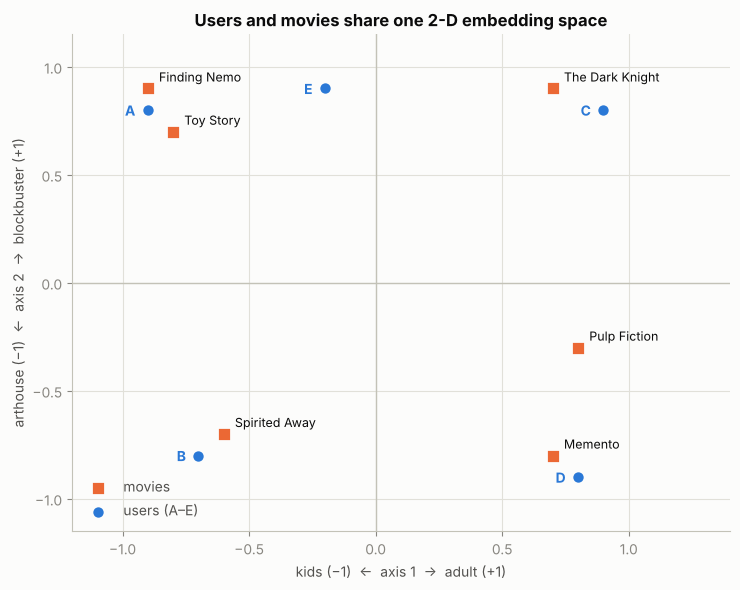

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 6))
ax.axhline(0, color=AXIS, lw=1); ax.axvline(0, color=AXIS, lw=1)
ax.scatter(toy_movies.kids_adult, toy_movies.arthouse_blockbuster, s=90, marker="s", color=ORANGE,
           edgecolor="#fcfcfb", linewidth=2, label="movies", zorder=3)
ax.scatter(toy_users.kids_adult, toy_users.arthouse_blockbuster, s=90, marker="o", color=BLUE,
           edgecolor="#fcfcfb", linewidth=2, label="users (A–E)", zorder=3)
for name, (x, y) in toy_movies.iterrows():
    ax.annotate(name, (x, y), xytext=(8, 5), textcoords="offset points", color=INK, fontsize=9)
for name, (x, y) in toy_users.iterrows():            # users labelled by letter (full names in the tables above)
    ax.annotate(name.split(":")[0], (x, y), xytext=(-9, -4), textcoords="offset points", ha="right",
                color=BLUE, fontsize=10, fontweight="bold")
ax.set_xlim(-1.2, 1.4); ax.set_ylim(-1.15, 1.15)
ax.set_xlabel("kids (−1)  ←  axis 1  →  adult (+1)")
ax.set_ylabel("arthouse (−1)  ←  axis 2  →  blockbuster (+1)")
ax.set_title("Users and movies share one 2-D embedding space")
ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

**Reading the tables and the plot:**
* In 1-D, users C and D get exactly the same score for *The Dark Knight*, because both sit on the adult side. In 2-D, C's score is strongly positive and D's is negative, because the second axis separates blockbuster fans from arthouse fans.
* In the plot, a user scores a movie highly when both points lie in the **same direction** from the origin (small angle, large dot product).

### 1.5 The key insight: the embeddings are *learned*, not designed
The numbers above were picked by hand. Real collaborative filtering does **not** need anyone to invent the axes or label each movie. Matrix factorization (Phases 4–7) starts every user and every movie with *random* vectors. It then repeatedly adjusts them (by gradient descent or alternating least squares) until the dot product ⟨user, movie⟩ reproduces the ratings that were actually observed.

**What "learning embeddings automatically" means:** the only input is the `users × items` feedback matrix. The model discovers on its own whatever latent axes best explain who liked what. These axes may correspond to "kids vs. adult" or "blockbuster vs. arthouse", but often they are mixtures that have no human name. We can only interpret them afterwards, by looking at which movies sit close together (Phase 6.6 does this for the trained model).

### 1.6 Why users and items can live in the *same* space
Users and movies are different kinds of things, but the embedding space is just a **shared coordinate system for measuring affinity**. A movie's coordinates say "how much of each latent trait it has". A user's coordinates say "how much they like each latent trait". Because both are expressed on the same axes, a similarity measure (dot product or cosine) between a user vector and a movie vector is meaningful. So is a similarity between two movies (item-item) or between two users (user-user).

---
# Phase 2 — Memory-Based CF: User-Based Filtering

### 2.1 The idea
To predict how user `u` will rate movie `i`: find the `k` users **most similar to `u` who have rated `i`**, and take a similarity-weighted average of *their* ratings of `i`. It is called "memory-based" because there is no training step. The method keeps the whole rating matrix in memory and compares users at prediction time.

### 2.2 Pearson similarity between two users (Task 3's correlation, on co-rated movies only)
$$\text{sim}(u,v) = \frac{\text{Cov}(r_u, r_v)}{\sigma_u\,\sigma_v} = \frac{\sum_{i \in I_{uv}} (r_{ui}-\bar r_u)(r_{vi}-\bar r_v)}{\sqrt{\sum_{i \in I_{uv}} (r_{ui}-\bar r_u)^2}\;\sqrt{\sum_{i \in I_{uv}} (r_{vi}-\bar r_v)^2}}$$
where $I_{uv}$ is the set of movies **both** users rated, and the means $\bar r_u, \bar r_v$ are taken over those co-rated movies.
A pair with fewer than `MIN_COMMON = 10` co-rated movies gets no similarity, because a correlation from 2–3 points is noise.

### 2.3 A subset, for compute reasons
The readme asks for a small subset. We take the **300 most-rated movies** and the **150 users who rated the most of them**. That gives a dense core where similarities rest on many co-rated movies.

In [6]:
N_CORE_MOVIES, N_CORE_USERS, MIN_COMMON, K_NEIGHBOURS = 300, 150, 10, 20

core_movies = n_ratings_of.index[:N_CORE_MOVIES]
core = ratings[ratings.movieId.isin(core_movies)]
core_users = core.userId.value_counts().index[:N_CORE_USERS]
core = core[core.userId.isin(core_users)]

# users x movies rating matrix, NaN = not rated
R_core = core.pivot(index="userId", columns="movieId", values="rating")
print(f"Core matrix: {R_core.shape[0]} users x {R_core.shape[1]} movies, "
      f"{R_core.notna().mean().mean():.1%} filled (full MovieLens: {density:.2%})")

Core matrix: 150 users x 300 movies, 43.4% filled (full MovieLens: 1.70%)


### 2.4 Hold out one rating
The prediction will be checked against a real rating, so that rating must be removed **before** any similarity is computed. Otherwise it would leak into the user's mean and into the similarities.

**Target:** *The Matrix (1999)*. We pick a core user who gave it **3.5**, below the movie's overall average of about 4.2. A naive "everyone loves *The Matrix*" guess would be too high for this user, so it is a fair test of whether CF picks up their personal taste. (Rule: the lowest `userId` in the core with a 3.5 rating; nothing else was tried.)

In [7]:
TARGET_MOVIE = 2571                                    # The Matrix (1999)
TARGET_USER = int(R_core.index[R_core[TARGET_MOVIE] == 3.5].min())
true_rating = R_core.loc[TARGET_USER, TARGET_MOVIE]

R_core_train = R_core.copy()
R_core_train.loc[TARGET_USER, TARGET_MOVIE] = np.nan    # held out

print(f"Target user {TARGET_USER} | movie: {title_of[TARGET_MOVIE]} | held-out true rating: {true_rating}")
print(f"User {TARGET_USER} has {R_core_train.loc[TARGET_USER].notna().sum()} other ratings in the core; "
      f"mean = {R_core_train.loc[TARGET_USER].mean():.3f}")
print(f"Average rating of {title_of[TARGET_MOVIE]} across all MovieLens users: "
      f"{ratings.loc[ratings.movieId == TARGET_MOVIE, 'rating'].mean():.3f}")

Target user 63 | movie: Matrix, The (1999) | held-out true rating: 3.5
User 63 has 145 other ratings in the core; mean = 3.597
Average rating of Matrix, The (1999) across all MovieLens users: 4.192


### 2.5 Build the user-user Pearson similarity matrix
`pearson_corated()` computes the formula from 2.2 for **all pairs at once** using matrix products: sums over co-rated movies become `X @ M.T`, where `M` is the 0/1 "rated" mask. It is then checked against pandas' pairwise-complete `corr()`, which implements the same definition.

In [8]:
def pearson_corated(R, min_common=MIN_COMMON):
    # R: users x items array with NaN for missing. Returns users x users Pearson over co-rated items.
    M = (~np.isnan(R)).astype(float)          # 1 where rated
    X = np.nan_to_num(R)                      # ratings, 0 where missing
    n   = M @ M.T                             # number of co-rated items for each pair
    sx  = X @ M.T                             # sum of u's ratings on items v also rated   [u, v]
    sy  = M @ X.T                             # sum of v's ratings on items u also rated   [u, v]
    sxx = (X ** 2) @ M.T
    syy = M @ (X ** 2).T
    sxy = X @ X.T
    with np.errstate(divide="ignore", invalid="ignore"):
        cov = sxy - sx * sy / n
        var_x = sxx - sx ** 2 / n
        var_y = syy - sy ** 2 / n
        sim = cov / np.sqrt(var_x * var_y)
    sim[(n < min_common) | ~np.isfinite(sim)] = np.nan
    return sim

t0 = time.perf_counter()
user_sim = pd.DataFrame(pearson_corated(R_core_train.values), index=R_core_train.index, columns=R_core_train.index)
t_user_sim = time.perf_counter() - t0

# Cross-check against pandas (pairwise-complete Pearson = same definition)
pandas_sim = R_core_train.T.corr(method="pearson", min_periods=MIN_COMMON)
print("matches pandas .corr():", np.allclose(user_sim.values, pandas_sim.values, atol=1e-8, equal_nan=True))
print(f"user-user matrix: {user_sim.shape}, built in {t_user_sim*1000:.1f} ms")

off_diag = user_sim.values[~np.eye(len(user_sim), dtype=bool)]
print(f"similarities: mean {np.nanmean(off_diag):.3f}, positive {np.mean(off_diag[~np.isnan(off_diag)] > 0):.1%}, "
      f"missing (<{MIN_COMMON} co-rated) {np.isnan(off_diag).mean():.1%}")
display(user_sim.iloc[:8, :8].round(2))

matches pandas .corr(): True
user-user matrix: (150, 150), built in 9.6 ms
similarities: mean 0.157, positive 80.0%, missing (<10 co-rated) 0.1%


userId,1,6,7,18,19,21,28,41
userId,,,,,,,,
1,1.00,-0.40,-0.18,0.22,0.45,-0.02,0.01,-0.16
6,-0.40,1.00,0.00,-0.17,0.00,0.25,-0.20,-0.27
7,-0.18,0.00,1.00,0.18,0.13,-0.06,-0.13,-0.33
18,0.22,-0.17,0.18,1.00,0.35,-0.08,0.26,0.09
19,0.45,0.00,0.13,0.35,1.00,-0.30,0.11,-0.02
21,-0.02,0.25,-0.06,-0.08,-0.30,1.00,-0.05,-0.18
28,0.01,-0.20,-0.13,0.26,0.11,-0.05,1.00,-0.01
41,-0.16,-0.27,-0.33,0.09,-0.02,-0.18,-0.01,1.00


In [9]:
# Verify one entry by hand with the Task 3 formula, on the co-rated movies only
u, v = TARGET_USER, user_sim.loc[TARGET_USER].drop(TARGET_USER).idxmax()
both = R_core_train.loc[[u, v]].dropna(axis=1)            # movies both rated
ru, rv = both.loc[u].values, both.loc[v].values
cov = np.sum((ru - ru.mean()) * (rv - rv.mean()))
sim_manual = cov / (np.sqrt(np.sum((ru - ru.mean()) ** 2)) * np.sqrt(np.sum((rv - rv.mean()) ** 2)))
print(f"users {u} & {v}: {both.shape[1]} co-rated movies")
print(f"Cov-numerator = {cov:.3f} | manual Pearson = {sim_manual:.4f} | matrix value = {user_sim.loc[u, v]:.4f}")

users 63 & 219: 109 co-rated movies
Cov-numerator = 42.743 | manual Pearson = 0.4829 | matrix value = 0.4829


### 2.6 The prediction formula
$$\text{pred}(u,i) = \bar r_u + \frac{\sum_{v \in N_k(u,i)} \text{sim}(u,v)\,(r_{vi} - \bar r_v)}{\sum_{v \in N_k(u,i)} |\text{sim}(u,v)|}$$

**Why centre on each user's mean?** Users use the rating scale differently. A generous rater's "4" is a lukewarm vote, while a harsh rater's "4" is high praise. So each neighbour contributes how far their rating of `i` sits **above or below their own average** ($r_{vi} - \bar r_v$). That deviation is applied to **the target user's** average $\bar r_u$. The question becomes "do similar users like this movie *more than they usually like movies*?" instead of "what number did they type?".

$N_k(u,i)$ = the `K_NEIGHBOURS = 20` users most similar to `u` who rated `i`. Here the means $\bar r_v$ are each user's mean over the core training matrix.

In [10]:
def predict_user_based(R, sim, u_idx, i_idx, k=K_NEIGHBOURS, user_means=None, return_table=False):
    # R: users x items (NaN = missing), sim: users x users. Returns (prediction, n_neighbours[, table]).
    if user_means is None:                                 # pass precomputed means when predicting many ratings
        user_means = np.nanmean(R, axis=1)
    raters = np.flatnonzero(~np.isnan(R[:, i_idx]))
    raters = raters[raters != u_idx]
    s = sim[u_idx, raters]
    ok = ~np.isnan(s)
    raters, s = raters[ok], s[ok]
    if len(raters) == 0:
        return user_means[u_idx], 0
    top = np.argsort(-s)[:k]
    nb, s = raters[top], s[top]
    dev = R[nb, i_idx] - user_means[nb]
    den = np.abs(s).sum()
    pred = user_means[u_idx] + (s * dev).sum() / den if den > 0 else user_means[u_idx]
    pred = float(np.clip(pred, 0.5, 5.0))
    if return_table:
        table = pd.DataFrame({"sim(u,v)": s, "r_vi": R[nb, i_idx], "mean r_v": user_means[nb],
                              "r_vi - mean": dev, "sim x dev": s * dev}, index=nb)   # index = row positions
        return pred, len(nb), table
    return pred, len(nb)

R_arr = R_core_train.values
u_idx = R_core_train.index.get_loc(TARGET_USER)
i_idx = R_core_train.columns.get_loc(TARGET_MOVIE)

t0 = time.perf_counter()
pred_user, k_used, nb_table = predict_user_based(R_arr, user_sim.values, u_idx, i_idx, return_table=True)
t_user_pred = time.perf_counter() - t0
nb_table.index = pd.Index(R_core_train.index[nb_table.index], name="neighbour userId")
print(f"{k_used} neighbours used (the {K_NEIGHBOURS} most similar users who rated {title_of[TARGET_MOVIE]})")
display(nb_table.round(3))

20 neighbours used (the 20 most similar users who rated Matrix, The (1999))


,"sim(u,v)",r_vi,mean r_v,r_vi - mean,sim x dev
neighbour userId,,,,,
219,0.483,5.0,3.503,1.497,0.723
509,0.471,3.5,3.495,0.005,0.002
160,0.440,4.0,3.288,0.712,0.313
254,0.438,5.0,4.146,0.854,0.375
448,0.437,2.0,3.620,-1.620,-0.708
593,0.434,2.5,3.222,-0.722,-0.313
57,0.425,5.0,3.809,1.191,0.507
286,0.418,4.5,3.905,0.595,0.249
105,0.418,4.0,4.089,-0.089,-0.037


In [11]:
r_bar_u = np.nanmean(R_arr[u_idx])
num = nb_table["sim x dev"].sum()
den = nb_table["sim(u,v)"].abs().sum()
print("Hand-worked user-based prediction")
print(f"  mean rating of user {TARGET_USER}           r̄_u = {r_bar_u:.4f}")
print(f"  numerator   Σ sim·(r_vi − r̄_v)        = {num:.4f}")
print(f"  denominator Σ |sim|                    = {den:.4f}")
print(f"  pred = {r_bar_u:.4f} + {num:.4f} / {den:.4f} = {r_bar_u:.4f} + {num/den:.4f} = {r_bar_u + num/den:.4f}")
print(f"  -> clipped to the 0.5-5 scale          = {pred_user:.3f}")
print(f"\n  held-out TRUE rating                   = {true_rating}")
print(f"  error (pred − true)                    = {pred_user - true_rating:+.3f}")

# Context: the two simplest guesses
item_mean_core = np.nanmean(R_arr[:, i_idx])
print(f"\n  naive guess 1 - movie's mean in core   = {item_mean_core:.3f} (error {item_mean_core - true_rating:+.3f})")
print(f"  naive guess 2 - user's own mean        = {r_bar_u:.3f} (error {r_bar_u - true_rating:+.3f})")

Hand-worked user-based prediction
  mean rating of user 63           r̄_u = 3.5966
  numerator   Σ sim·(r_vi − r̄_v)        = 2.4292
  denominator Σ |sim|                    = 7.7450
  pred = 3.5966 + 2.4292 / 7.7450 = 3.5966 + 0.3136 = 3.9102
  -> clipped to the 0.5-5 scale          = 3.910

  held-out TRUE rating                   = 3.5
  error (pred − true)                    = +0.410

  naive guess 1 - movie's mean in core   = 4.140 (error +0.640)
  naive guess 2 - user's own mean        = 3.597 (error +0.097)


**Reading the result:** the 20 most similar users rated *The Matrix* clearly **above their own averages** (the net weighted deviation is positive), so CF lifts user 63's prediction from their mean of 3.60 to 3.91. It is closer to the truth than the "movie's average" guess (4.14), but user 63 turns out to be lukewarm on *The Matrix* compared with people of similar taste. Their own mean (3.60) happened to be the better guess for this one rating. A single prediction is an anecdote, not an evaluation. **Exercise 1** runs the same method over 13,579 held-out ratings, where user-based CF (RMSE 0.838) clearly beats the user's-mean baseline (0.913).

### 2.7 User-based CF's core weakness
* **Scaling:** the user-user matrix has `m²` entries for `m` users, i.e. `O(m²)` pairs, and each pair costs work proportional to the number of items. The 150-user subset has ~11k pairs, all 610 users have ~186k, and a service with 100 million users would need ~5×10¹⁵ pairs. That is not feasible.
* **Staleness:** every new rating changes that user's mean and their similarity to everyone else. Every new user needs a new row and column. The matrix must be recomputed constantly, because a user's taste and their pool of "similar users" keep shifting.

In [12]:
for m in [N_CORE_USERS, n_users, 1_000_000, 100_000_000]:
    print(f"{m:>12,} users -> {m*(m-1)//2:>22,} user pairs")

         150 users ->                 11,175 user pairs
         610 users ->                185,745 user pairs
   1,000,000 users ->        499,999,500,000 user pairs
 100,000,000 users ->  4,999,999,950,000,000 user pairs


---
# Phase 3 — Memory-Based CF: Item-Based Filtering

### 3.1 The idea
Flip the question. To predict how user `u` will rate movie `i`, find the movies **most similar to `i` that `u` has already rated**, and take a similarity-weighted average of `u`'s **own** ratings of them: "you rated these similar movies highly, so you will probably like this one too".

### 3.2 Adjusted cosine similarity between two items
$$\text{adjcos}(i,j) = \frac{\sum_{u \in U_{ij}} (r_{ui}-\bar r_u)(r_{uj}-\bar r_u)}{\sqrt{\sum_{u \in U_{ij}}(r_{ui}-\bar r_u)^2}\;\sqrt{\sum_{u \in U_{ij}}(r_{uj}-\bar r_u)^2}}$$
summed over users $U_{ij}$ who rated **both** items. The subtraction uses each **user's** mean $\bar r_u$ (over all their ratings).

**Why "adjusted":** plain cosine on raw ratings treats a harsh rater's 2 and a generous rater's 4 as different opinions, even though both may mean "average for me". All raw ratings are positive, so plain cosine between any two movies is high and differences are hard to see. Subtracting each user's own mean turns ratings into "liked more / less than usual". (Pearson-on-items would subtract the *item's* mean instead. Adjusted cosine subtracts the *user's* mean, because the scale problem comes from users. Exercise 5 shows the difference on a toy matrix.)

In [13]:
def adjusted_cosine(R, min_common=MIN_COMMON):
    # R: users x items array with NaN for missing. Returns items x items adjusted cosine
    # (sums over users who rated BOTH items, ratings centred by each user's mean).
    M = (~np.isnan(R)).astype(float)
    user_mean = np.nanmean(R, axis=1, keepdims=True)
    C = np.nan_to_num(R - user_mean)                        # centred, 0 where missing
    num = C.T @ C                                           # only co-rated users contribute
    den = np.sqrt((C ** 2).T @ M) * np.sqrt(M.T @ (C ** 2)) # each norm restricted to co-raters
    n = M.T @ M
    with np.errstate(divide="ignore", invalid="ignore"):
        sim = num / den
    sim[(n < min_common) | ~np.isfinite(sim)] = np.nan
    return sim

t0 = time.perf_counter()
item_sim = pd.DataFrame(adjusted_cosine(R_core_train.values), index=R_core_train.columns, columns=R_core_train.columns)
t_item_sim = time.perf_counter() - t0
print(f"item-item matrix: {item_sim.shape}, built in {t_item_sim*1000:.1f} ms")
display(item_sim.iloc[:6, :6].rename(index=title_of, columns=lambda m: title_of[m][:18]).round(2))

item-item matrix: (300, 300), built in 12.6 ms


movieId,Toy Story (1995),Jumanji (1995),Heat (1995),GoldenEye (1995),American President,Casino (1995)
movieId,,,,,,
Toy Story (1995),1.00,0.03,-0.24,-0.30,-0.11,-0.27
Jumanji (1995),0.03,1.00,-0.05,-0.08,0.17,-0.40
Heat (1995),-0.24,-0.05,1.00,0.37,0.40,0.48
GoldenEye (1995),-0.30,-0.08,0.37,1.00,0.50,0.28
"American President, The (1995)",-0.11,0.17,0.40,0.50,1.00,0.29
Casino (1995),-0.27,-0.40,0.48,0.28,0.29,1.00


In [14]:
# Sanity check: what does item-item CF think is most similar to The Matrix? (no genre data used)
most_similar = item_sim[TARGET_MOVIE].drop(TARGET_MOVIE).sort_values(ascending=False).head(8)
display(pd.DataFrame({"adjusted cosine": most_similar.round(3).values,
                      "genres": ["|".join(genres_of[m]) for m in most_similar.index]},
                     index=pd.Index(titles(most_similar.index), name=f"most similar to {title_of[TARGET_MOVIE]}")))

,adjusted cosine,genres
"most similar to Matrix, The (1999)",,
Office Space (1999),0.544,Comedy|Crime
Saving Private Ryan (1998),0.484,Action|Drama|War
Batman Begins (2005),0.474,Action|Crime|IMAX
"Dark Knight Rises, The (2012)",0.442,Action|Adventure|Crime|IMAX
Full Metal Jacket (1987),0.438,Drama|War
Sin City (2005),0.424,Action|Crime|Film-Noir|Mystery|Thriller
Memento (2000),0.424,Mystery|Thriller
"Usual Suspects, The (1995)",0.403,Crime|Mystery|Thriller


No genre information was used, yet the neighbours are mostly action/crime/thriller films of the same era (*Batman Begins*, *The Dark Knight Rises*, *Memento*, *Sin City*). The top match, *Office Space* (a comedy), is the interesting one. It shares *The Matrix*'s **audience** (late-90s cult favourites), not its genre. That is collaborative filtering finding behavioural similarity that a content-based model from Task 11 could never see.

### 3.3 The item-based prediction (same user, same held-out movie)
$$\text{pred}(u,i) = \frac{\sum_{j \in N_k(i;u)} \text{sim}(i,j)\, r_{uj}}{\sum_{j \in N_k(i;u)} |\text{sim}(i,j)|}$$
$N_k(i;u)$ = the `k = 20` movies most similar to `i` that `u` has rated, keeping **positive** similarities only. A weighted average of raw ratings with negative weights can leave the 0.5–5 scale, and "dissimilar to The Matrix" says little about how much `u` will like The Matrix.

In [15]:
def predict_item_based(R, sim, u_idx, i_idx, k=K_NEIGHBOURS, return_table=False):
    # R: users x items (NaN = missing), sim: items x items. Weighted average of the user's own ratings.
    rated = np.flatnonzero(~np.isnan(R[u_idx]))
    rated = rated[rated != i_idx]
    s = sim[i_idx, rated]
    ok = ~np.isnan(s) & (s > 0)
    rated, s = rated[ok], s[ok]
    if len(rated) == 0:
        return float(np.nanmean(R[u_idx])), 0                # fallback: user's mean
    top = np.argsort(-s)[:k]
    nb, s = rated[top], s[top]
    pred = float(np.clip((s * R[u_idx, nb]).sum() / np.abs(s).sum(), 0.5, 5.0))
    if return_table:
        table = pd.DataFrame({"sim(i,j)": s, "r_uj (user's rating)": R[u_idx, nb], "sim x r_uj": s * R[u_idx, nb]},
                             index=nb)                                             # index = column positions
        return pred, len(nb), table
    return pred, len(nb)

t0 = time.perf_counter()
pred_item, k_used_item, item_table = predict_item_based(R_arr, item_sim.values, u_idx, i_idx, return_table=True)
t_item_pred = time.perf_counter() - t0
item_table.index = pd.Index(titles(R_core_train.columns[item_table.index]), name="similar movie j")
print(f"{k_used_item} similar movies used (the {K_NEIGHBOURS} most similar to {title_of[TARGET_MOVIE]} that user {TARGET_USER} rated)")
display(item_table.round(3))

num_i, den_i = item_table["sim x r_uj"].sum(), item_table["sim(i,j)"].abs().sum()
print("Hand-worked item-based prediction")
print(f"  pred = Σ sim·r_uj / Σ |sim| = {num_i:.4f} / {den_i:.4f} = {num_i/den_i:.4f}  ->  {pred_item:.3f}")
print(f"  held-out TRUE rating = {true_rating}   error = {pred_item - true_rating:+.3f}")

20 similar movies used (the 20 most similar to Matrix, The (1999) that user 63 rated)


,"sim(i,j)",r_uj (user's rating),sim x r_uj
similar movie j,,,
Saving Private Ryan (1998),0.484,3.5,1.695
Batman Begins (2005),0.474,3.5,1.660
"Dark Knight Rises, The (2012)",0.442,5.0,2.208
Full Metal Jacket (1987),0.438,2.5,1.096
Sin City (2005),0.424,5.0,2.119
Memento (2000),0.424,3.5,1.483
"Usual Suspects, The (1995)",0.403,5.0,2.017
Schindler's List (1993),0.398,4.0,1.593
Aliens (1986),0.394,2.5,0.984


Hand-worked item-based prediction
  pred = Σ sim·r_uj / Σ |sim| = 31.4189 / 7.9426 = 3.9557  ->  3.956
  held-out TRUE rating = 3.5   error = +0.456


In [16]:
cmp = pd.DataFrame({
    "prediction": [pred_user, pred_item],
    "error vs true 3.5": [pred_user - true_rating, pred_item - true_rating],
    "similarity matrix size": [f"{user_sim.shape[0]}×{user_sim.shape[1]} users", f"{item_sim.shape[0]}×{item_sim.shape[1]} movies"],
    "matrix build (ms)": [t_user_sim * 1000, t_item_sim * 1000],
    "one prediction (ms)": [t_user_pred * 1000, t_item_pred * 1000],
}, index=["user-based (Pearson)", "item-based (adjusted cosine)"])
display(cmp.round(3))

,prediction,error vs true 3.5,similarity matrix size,matrix build (ms),one prediction (ms)
user-based (Pearson),3.910,0.410,150×150 users,9.647,2.569
item-based (adjusted cosine),3.956,0.456,300×300 movies,12.552,0.873


### 3.4 User-based vs. item-based CF

| | User-based CF | Item-based CF |
|---|---|---|
| **Neighbours** | similar *users* who rated `i` | similar *items* that `u` rated |
| **Similarity matrix** | `m × m` (users) | `n × n` (items) |
| **Accuracy here** | held-out rating: 3.91 (true 3.5). **Exercise 1** (13,579 test ratings): RMSE **0.838**, 99.5% of ratings get neighbours | held-out rating: 3.96. **Exercise 1**: RMSE **0.852**, 98.5% coverage. Slightly worse here: many movies have only 20–50 raters, so item-item similarities are noisier |
| **Stability over time** | low: a user's taste and their set of similar users shift with every new rating | **high**: how *The Matrix* relates to *Terminator 2* barely changes once both have hundreds of ratings |
| **Offline precomputation** | hard: goes stale quickly | **easy**: precompute nightly and reuse; online cost is a lookup plus a weighted average |
| **Compute cost** | `O(m²)` pairs | `O(n²)` pairs. Note: MovieLens has *more* movies (9.7k) than users (610), so item-item is the bigger matrix *here*. In e-commerce users far outnumber items (hundreds of millions vs. millions), which flips this. |
| **Explainability** | "users like you liked this" (opaque: who are they?) | "because you rated *X* highly" (shows the user's own history) |

**Why production prefers item-based CF:** the item-item similarity matrix is far more stable, so it can be **computed offline once and reused**. Serving a recommendation is then cheap and the explanation is natural. This is the classic Amazon "customers who bought this also bought" design.

---
# Phase 4 — Matrix Factorization Fundamentals

### 4.1 The goal
Given the feedback matrix $A \in \mathbb{R}^{m \times n}$ (`m` users, `n` items), learn
* a **user embedding matrix** $U \in \mathbb{R}^{m \times d}$ (row `i` = user `i`'s `d`-dimensional embedding)
* an **item embedding matrix** $V \in \mathbb{R}^{n \times d}$ (row `j` = item `j`'s embedding)

such that $U V^\top \approx A$. Entry $(i,j)$ of $UV^\top$ is the dot product $\langle U_i, V_j\rangle$ from Phase 1. These are exactly the embeddings from Phase 1, now learned instead of hand-designed.

### 4.2 The basic objective (observed entries only)
$$\min_{U,V} \sum_{(i,j) \in \text{obs}} \left(A_{ij} - \langle U_i, V_j \rangle\right)^2$$

In [17]:
d = 20
m_, n_ = n_users, n_movies_rated
print(f"MovieLens feedback matrix A: {m_} x {n_} = {m_*n_:,} cells, only {len(ratings):,} observed ({density:.2%})")
print(f"With d = {d}: U is {m_}x{d}, V is {n_}x{d} -> {(m_ + n_) * d:,} parameters "
      f"({(m_ + n_) * d / (m_ * n_):.1%} of the cell count)")

# What 'treat every missing entry as 0' would mean on the real data
print(f"\nIf missing = 0: the average 'rating' the model would see is {ratings.rating.sum() / (m_ * n_):.3f} stars "
      f"(true mean of real ratings: {ratings.rating.mean():.2f})")

MovieLens feedback matrix A: 610 x 9724 = 5,931,640 cells, only 100,836 observed (1.70%)
With d = 20: U is 610x20, V is 9724x20 -> 206,680 parameters (3.5% of the cell count)

If missing = 0: the average 'rating' the model would see is 0.060 stars (true mean of real ratings: 3.50)


### 4.3 Why "treat every unobserved entry as 0 and sum over the whole matrix" is a bad idea
98.3% of the cells are empty. If every empty cell is a **0 = "not interested"** target, almost all of the loss comes from those zeros. The cheapest way to reduce it is to predict ≈ 0 for everything. The average target the model sees is about 0.06 stars, while real ratings average 3.5. Worse, it teaches the model that a movie a user **hasn't seen yet** is a movie they **dislike**. Those unseen movies are exactly the ones we want to recommend.

### 4.4 Why plain SVD of the observed-only problem fails in practice
* `np.linalg.svd` needs a **complete** matrix, so the missing 98% must be filled with *something*. Filling with 0 is the problem above. Filling with the user's mean is an arbitrary guess that the SVD then treats as real data, and it outnumbers the real data 60 to 1.
* SVD minimises error over **all** cells equally and cannot be told "only these 1.7% matter".
* A dense SVD of a big catalogue is also impractical: a 100M × 1M dense matrix cannot even be stored.

Below, SVD first works perfectly on a **dense** toy matrix (reusing Task 10's SVD) and then fails once entries are hidden.

In [18]:
# A dense toy rating matrix generated from the Phase 1 story: rating ~ 3 + 2.2 x <user, movie> (rounded to half-stars)
toy_users_4 = toy_users.copy()
A_toy = np.clip(np.round((3 + 2.2 * toy_users_4.values @ toy_movies.values.T) * 2) / 2, 1, 5)
A_toy = pd.DataFrame(A_toy, index=toy_users_4.index, columns=toy_movies.index)
print("Dense toy ratings (5 users x 6 movies):")
display(A_toy)

U_s, S_s, Vt_s = np.linalg.svd(A_toy.values, full_matrices=False)
print("singular values:", S_s.round(3))
print("share of total 'energy' (sum of squares) per component:", (S_s**2 / (S_s**2).sum()).round(3))

def rank_k(U_s, S_s, Vt_s, k):
    return U_s[:, :k] @ np.diag(S_s[:k]) @ Vt_s[:k]

for k in [1, 2, 3]:
    rec = rank_k(U_s, S_s, Vt_s, k)
    print(f"rank-{k} reconstruction RMSE: {np.sqrt(np.mean((rec - A_toy.values) ** 2)):.3f}")

Dense toy ratings (5 users x 6 movies):


,Finding Nemo,Toy Story,Spirited Away,The Dark Knight,Pulp Fiction,Memento
A: kids + blockbusters,5.0,5.0,3.0,3.0,1.0,1.0
B: kids + arthouse,3.0,3.0,5.0,1.0,2.5,3.5
C: adult + blockbusters,3.0,2.5,1.0,5.0,4.0,3.0
D: adult + arthouse,1.0,1.0,3.5,2.5,5.0,5.0
E: family blockbusters,5.0,4.5,2.0,4.5,2.0,1.0


singular values: [16.775  6.561  4.379  0.297  0.18 ]
share of total 'energy' (sum of squares) per component: [0.819 0.125 0.056 0.    0.   ]
rank-1 reconstruction RMSE: 1.442
rank-2 reconstruction RMSE: 0.802
rank-3 reconstruction RMSE: 0.063


In [19]:
# The rank-3 reconstruction, written as MF embeddings: U_emb = U_k √S_k, V_emb = V_k √S_k  ->  U_emb V_embᵀ = rank-k approx
k = 3
U_emb = U_s[:, :k] * np.sqrt(S_s[:k])
V_emb = Vt_s[:k].T * np.sqrt(S_s[:k])
rec3 = pd.DataFrame(U_emb @ V_emb.T, index=A_toy.index, columns=A_toy.columns)
print("Rank-3 reconstruction U_emb · V_embᵀ:")
display(rec3.round(2))
print("absolute error:")
display((rec3 - A_toy).abs().round(2))

Rank-3 reconstruction U_emb · V_embᵀ:


,Finding Nemo,Toy Story,Spirited Away,The Dark Knight,Pulp Fiction,Memento
A: kids + blockbusters,5.07,4.89,3.05,3.01,1.03,0.94
B: kids + arthouse,2.93,3.05,5.02,1.01,2.52,3.46
C: adult + blockbusters,2.96,2.48,1.08,5.03,4.06,2.89
D: adult + arthouse,1.06,0.97,3.46,2.48,4.96,5.07
E: family blockbusters,4.98,4.59,1.90,4.46,1.93,1.14


absolute error:


,Finding Nemo,Toy Story,Spirited Away,The Dark Knight,Pulp Fiction,Memento
A: kids + blockbusters,0.07,0.11,0.05,0.01,0.03,0.06
B: kids + arthouse,0.07,0.05,0.02,0.01,0.02,0.04
C: adult + blockbusters,0.04,0.02,0.08,0.03,0.06,0.11
D: adult + arthouse,0.06,0.03,0.04,0.02,0.04,0.07
E: family blockbusters,0.02,0.09,0.10,0.04,0.07,0.14


**Dense case:** three components hold almost all of the energy. The first is mostly the overall "everyone rates around 3" level, and the next two are the two taste axes from Phase 1. Rank 3 reproduces the matrix to within the half-star rounding. On a *complete* matrix, SVD gives the best possible rank-k factorization.

Now hide a third of the entries, which is still far denser than MovieLens's 1.7%, and let SVD guess them back.

In [20]:
rng = np.random.default_rng(SEED)
mask_obs = np.ones(A_toy.shape, dtype=bool)
hidden_cells = rng.choice(A_toy.size, size=10, replace=False)
mask_obs.flat[hidden_cells] = False
A_obs = A_toy.values.copy(); A_obs[~mask_obs] = np.nan
print(f"observed {mask_obs.sum()} of {A_toy.size} cells, hidden {(~mask_obs).sum()}")

def hidden_rmse(pred):
    return np.sqrt(np.mean((pred[~mask_obs] - A_toy.values[~mask_obs]) ** 2))

zero_filled = np.nan_to_num(A_obs, nan=0.0)
mean_filled = np.where(mask_obs, A_obs, np.nanmean(A_obs, axis=1, keepdims=True))
rows = []
for name, filled in [("missing = 0", zero_filled), ("missing = user's mean", mean_filled)]:
    Uf, Sf, Vtf = np.linalg.svd(filled, full_matrices=False)
    for k in [2, 3]:
        pred = rank_k(Uf, Sf, Vtf, k)
        rows.append({"fill strategy": name, "rank k": k,
                     "RMSE on hidden cells": hidden_rmse(pred),
                     "mean prediction on hidden cells": pred[~mask_obs].mean()})
svd_fill_results = pd.DataFrame(rows)
print(f"true mean of the hidden cells: {A_toy.values[~mask_obs].mean():.2f}")
display(svd_fill_results.round(3))

observed 20 of 30 cells, hidden 10
true mean of the hidden cells: 3.15


,fill strategy,rank k,RMSE on hidden cells,mean prediction on hidden cells
0,missing = 0,2,2.743,0.885
1,missing = 0,3,3.335,0.331
2,missing = user's mean,2,1.592,3.090
3,missing = user's mean,3,1.455,3.191


**What happened:**
* **Zero-filled SVD** predicts the hidden cells far too low, because it faithfully reconstructs the fake zeros. With 98% zeros, as in MovieLens, this would be much worse still.
* **Mean-filled SVD** is less wrong, but only because the guess we filled in was reasonable. The model learns our fill-in, not the users' taste.

The fix is to factorize using **only the observed cells**, optionally plus a small, controlled pull on the unobserved ones. That needs an optimizer (SGD or WALS) instead of a closed-form SVD, which is Phase 5. The same hidden cells are revisited there.

### 4.5 Choosing the embedding dimension `d`
We use **d = 20** for the MovieLens models.
* **Too small** (e.g. d = 2–5): underfits. A few axes cannot capture the many independent tastes in a catalogue (genre, era, tone, language, actor…).
* **Too large** (e.g. d = 100+): overfits. Each user has a median of only ~70 ratings, and with many free parameters per user the model memorises noise. Training and serving also get slower, because each score is a d-length dot product and the index stores `(m+n)·d` floats.
* **d = 20** is a common middle ground for a dataset this small. **Exercise 2** measures train vs. test RMSE for d = 5, 20, 50 and 100.

---
# Phase 5 — Weighted Matrix Factorization: SGD vs. WALS

### 5.1 The Weighted Matrix Factorization (WMF) objective
Phase 4 left two bad options: sum over the **observed** cells only, or treat **every** cell as observed, with missing cells as 0. WMF takes the middle road. It splits the loss into two sums and **down-weights** the unobserved one with a hyperparameter $w_0$:

$$\min_{U,V}\; \underbrace{\sum_{(i,j)\in \text{obs}} \big(A_{ij} - \langle U_i,V_j\rangle\big)^2}_{\text{fit what users did}} \;+\; w_0 \underbrace{\sum_{(i,j)\notin \text{obs}} \big(0 - \langle U_i,V_j\rangle\big)^2}_{\text{gentle pull toward "not interested"}} \;+\; \lambda\big(\lVert U\rVert^2 + \lVert V\rVert^2\big)$$

The last term is ordinary L2 regularization, as in Task 7's ridge regression.

### 5.2 What $w_0$ controls
* $w_0 = 0$: only the observed term exists, which is the observed-only objective with its trivial solution (shown next).
* $w_0 = 1$: every unobserved cell counts as much as a real interaction, which is the "missing = 0" model from Phase 4.3.
* Small $w_0$ (≈ 0.01–0.1): unobserved pairs are nudged toward "not interested", but weakly enough that **one real interaction outweighs many unknowns**.

So $w_0$ balances **how much the model is penalised for getting real interactions wrong** against **how strongly it is pushed to predict "not interested" for pairs it has never seen**.

### Why the observed-only objective collapses (implicit data)
With implicit data every observed entry is **1** ("watched"). Then $U_i = V_j = (1/\sqrt d, \dots, 1/\sqrt d)$ for *every* user and item gives $\langle U_i,V_j\rangle = 1$ everywhere. That is **zero** observed-only loss, and it predicts "will watch" for every movie, which is useless for ranking. Only the $w_0$ term penalises it.

To show this, the toy below is built from the Phase 1 story: 40 users and 24 movies with hidden 2-D tastes (the four quadrants of the Phase 1 plot). Each user "watched" the 7 movies that best match their taste, and one watched movie per user is **hidden** as a test item.

In [21]:
rng = np.random.default_rng(SEED)
quadrants = np.array([[-0.8, 0.8], [-0.8, -0.8], [0.8, 0.8], [0.8, -0.8]])        # kids/adult x arthouse/blockbuster
V_true = np.repeat(quadrants, 6, axis=0) + rng.normal(0, 0.15, (24, 2))          # 6 movies per quadrant
U_true = quadrants[rng.integers(0, 4, 40)] + rng.normal(0, 0.3, (40, 2))         # each user leans to one quadrant
watched = np.zeros((40, 24))
for u_ in range(40):
    watched[u_, np.argsort(-(U_true[u_] @ V_true.T))[:7]] = 1                     # the 7 best-matching movies

hidden_pos = np.zeros_like(watched)                                              # 1 hidden positive per user
for u_ in range(40):
    hidden_pos[u_, rng.choice(np.flatnonzero(watched[u_]))] = 1
A_imp = watched - hidden_pos                                                     # training matrix
obs_imp = A_imp > 0
print(f"toy implicit matrix {A_imp.shape}: {int(obs_imp.sum())} observed 1s, {int((~obs_imp).sum())} unobserved cells, "
      f"{int(hidden_pos.sum())} hidden test positives")

def wmf_loss(A, obs, U, V, w0, lam):
    P = U @ V.T
    return (((A - P) ** 2)[obs].sum() + w0 * (P ** 2)[~obs].sum()
            + lam * ((U ** 2).sum() + (V ** 2).sum()))

# The trivial solution: every user and item = (1/√2, 1/√2)
U_triv = np.full((40, 2), 1 / np.sqrt(2)); V_triv = np.full((24, 2), 1 / np.sqrt(2))
P_triv = U_triv @ V_triv.T
print(f"\ntrivial solution predicts {P_triv.min():.2f}..{P_triv.max():.2f} for every cell")
print(f"  observed-only loss (w0=0, λ=0): {wmf_loss(A_imp, obs_imp, U_triv, V_triv, w0=0.0, lam=0):.3f}   <- perfect score, useless model")
print(f"  WMF loss          (w0=0.1, λ=0): {wmf_loss(A_imp, obs_imp, U_triv, V_triv, w0=0.1, lam=0):.3f}  <- = 0.1 x {int((~obs_imp).sum())} unobserved cells")

toy implicit matrix (40, 24): 240 observed 1s, 720 unobserved cells, 40 hidden test positives

trivial solution predicts 1.00..1.00 for every cell
  observed-only loss (w0=0, λ=0): 0.000   <- perfect score, useless model
  WMF loss          (w0=0.1, λ=0): 72.000  <- = 0.1 x 720 unobserved cells


### 5.3 Two ways to minimise the WMF objective

**Stochastic Gradient Descent (SGD)** is the same optimizer as Task 7. Visit one cell $(i,j)$ at a time, compute the error $e = A_{ij} - \langle U_i, V_j\rangle$, and step both vectors along the negative gradient:
$$U_i \leftarrow U_i + \eta\,(w_{ij}\, e\, V_j - \tfrac{\lambda}{n} U_i), \qquad V_j \leftarrow V_j + \eta\,(w_{ij}\, e\, U_i - \tfrac{\lambda}{m} V_j)$$
with $w_{ij} = 1$ for observed cells and $w_0$ for unobserved ones. It is **generic**: any differentiable loss, extra bias terms or side features just add gradient terms. But it needs a learning rate $\eta$ and many epochs, and with millions of unobserved cells you have to *sample* them.

**Weighted Alternating Least Squares (WALS)** relies on one fact: with $V$ **fixed**, the objective is an ordinary weighted ridge regression in $U$ (quadratic, so it has a closed-form minimum), and the same holds the other way round. So it alternates:
1. Fix $V$, then solve every user exactly: $U_i = (V^\top W_i V + \lambda I)^{-1} V^\top W_i A_i$
2. Fix $U$, then solve every item exactly: $V_j = (U^\top W_j U + \lambda I)^{-1} U^\top W_j A_{:,j}$
3. Repeat until the loss stops falling.

Each user's solve is independent of every other user's, so step 1 **parallelises** across machines, and so does step 2. No learning rate is needed.

In [22]:
def wals(A, obs, d, w0, lam, sweeps, seed=SEED):
    r_ = np.random.default_rng(seed)
    U = r_.normal(0, 0.1, (A.shape[0], d)); V = r_.normal(0, 0.1, (A.shape[1], d))
    W = np.where(obs, 1.0, w0)                                  # weight of every cell
    A0 = np.where(obs, A, 0.0)                                  # unobserved target = 0
    history = [wmf_loss(A0, obs, U, V, w0, lam)]
    for _ in range(sweeps):
        for i in range(A.shape[0]):                             # fix V, solve each user (closed form)
            Wi = W[i]
            U[i] = np.linalg.solve((V.T * Wi) @ V + lam * np.eye(d), (V.T * Wi) @ A0[i])
        for j in range(A.shape[1]):                             # fix U, solve each item (closed form)
            Wj = W[:, j]
            V[j] = np.linalg.solve((U.T * Wj) @ U + lam * np.eye(d), (U.T * Wj) @ A0[:, j])
        history.append(wmf_loss(A0, obs, U, V, w0, lam))
    return U, V, history

def sgd_mf(A, obs, d, w0, lam, epochs, lr, seed=SEED):
    r_ = np.random.default_rng(seed)
    U = r_.normal(0, 0.1, (A.shape[0], d)); V = r_.normal(0, 0.1, (A.shape[1], d))
    W = np.where(obs, 1.0, w0)
    A0 = np.where(obs, A, 0.0)
    cells = np.argwhere(W > 0)                                  # every cell with non-zero weight
    m, n = A.shape
    history = [wmf_loss(A0, obs, U, V, w0, lam)]
    for _ in range(epochs):
        r_.shuffle(cells)
        for i, j in cells:
            e = A0[i, j] - U[i] @ V[j]
            Ui = U[i].copy()
            U[i] += lr * (W[i, j] * e * V[j] - lam / n * U[i])
            V[j] += lr * (W[i, j] * e * Ui - lam / m * V[j])
        history.append(wmf_loss(A0, obs, U, V, w0, lam))
    return U, V, history

def hidden_positive_rank(U, V, obs=obs_imp, hidden=hidden_pos):
    # Rank of each user's hidden movie among all movies they have not watched (1 = top).
    P = U @ V.T
    ranks = []
    for u_ in range(P.shape[0]):
        cand = np.flatnonzero(~obs[u_])
        order = cand[np.argsort(-P[u_, cand])]
        ranks.append(np.flatnonzero(order == np.flatnonzero(hidden[u_])[0])[0] + 1)
    return np.array(ranks)

W0, LAM, D_TOY = 0.1, 0.1, 2
runs = {}
t0 = time.perf_counter(); U_w, V_w, h = wals(A_imp, obs_imp, D_TOY, W0, LAM, sweeps=60); runs["WALS"] = (h, time.perf_counter() - t0, U_w, V_w)
for lr in [0.01, 0.05, 0.2]:
    t0 = time.perf_counter(); U_g, V_g, h = sgd_mf(A_imp, obs_imp, D_TOY, W0, LAM, epochs=60, lr=lr)
    runs[f"SGD lr={lr}"] = (h, time.perf_counter() - t0, U_g, V_g)

n_cand = int((~obs_imp[0]).sum())
summary = pd.DataFrame({
    name: {"passes over data": len(h) - 1, "time (s)": t, "final WMF loss": h[-1],
           "loss after 5 passes": h[5],
           "hidden item: mean rank": hidden_positive_rank(U_, V_).mean(),
           "hidden item: in top-3": (hidden_positive_rank(U_, V_) <= 3).mean()}
    for name, (h, t, U_, V_) in runs.items()}).T
print(f"Same objective for all runs (w0={W0}, λ={LAM}, d={D_TOY}). Random ranking would give mean rank ≈ {(n_cand + 1) / 2:.1f} "
      f"of {n_cand} and top-3 rate ≈ {3 / n_cand:.2f}.")
display(summary.round(3))

Same objective for all runs (w0=0.1, λ=0.1, d=2). Random ranking would give mean rank ≈ 9.5 of 18 and top-3 rate ≈ 0.17.


,passes over data,time (s),final WMF loss,loss after 5 passes,hidden item: mean rank,hidden item: in top-3
WALS,60.0,0.134,29.810,37.247,3.675,0.475
SGD lr=0.01,60.0,1.160,58.283,239.774,4.150,0.650
SGD lr=0.05,60.0,1.025,30.176,232.973,2.850,0.750
SGD lr=0.2,60.0,0.952,30.079,32.916,3.700,0.475


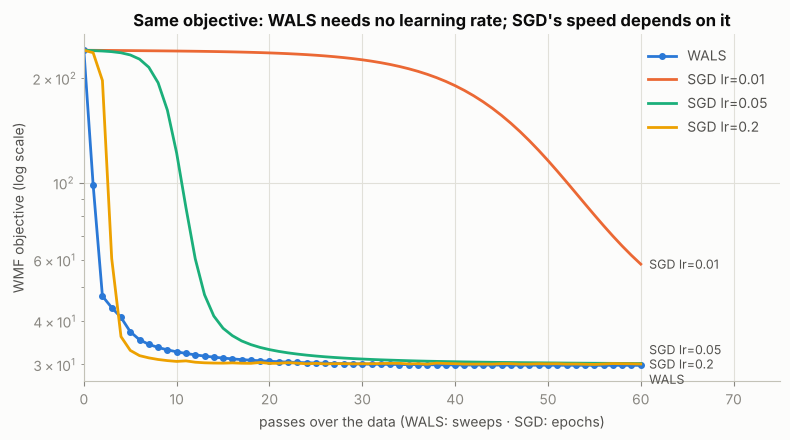

In [23]:
fig, ax = plt.subplots(figsize=(8, 4.5))
styles = {"WALS": (BLUE, "o"), "SGD lr=0.01": (ORANGE, None), "SGD lr=0.05": (AQUA, None), "SGD lr=0.2": (YELLOW, None)}
label_dy = {"WALS": -10, "SGD lr=0.01": 0, "SGD lr=0.05": 10, "SGD lr=0.2": 0}    # stagger labels that end at ~30
for name, (h, *_rest) in runs.items():
    color, marker = styles[name]
    ax.plot(range(len(h)), h, color=color, marker=marker, markersize=4 if marker else None, label=name)
    ax.annotate(name, (len(h) - 1, h[-1]), xytext=(6, label_dy[name]), textcoords="offset points",
                color=INK2, fontsize=9, va="center")
ax.set_yscale("log")
ax.set_xlabel("passes over the data (WALS: sweeps · SGD: epochs)")
ax.set_ylabel("WMF objective (log scale)")
ax.set_title("Same objective: WALS needs no learning rate; SGD's speed depends on it")
ax.set_xlim(0, 75)
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

### 5.4 The effect of $w_0$
Same toy and same WALS, now varying only $w_0$. The table averages 5 random initialisations so one lucky start does not decide the result.

In [24]:
rows = []
for w0 in [0.0, 0.01, 0.1, 0.5, 1.0]:
    stats = []
    for s in range(5):
        U_, V_, _ = wals(A_imp, obs_imp, D_TOY, w0, LAM, sweeps=15, seed=s)
        P = U_ @ V_.T
        rk = hidden_positive_rank(U_, V_)
        stats.append([P[obs_imp].mean(), P[~obs_imp].mean(), P[hidden_pos > 0].mean(), rk.mean(), (rk <= 3).mean()])
    rows.append([w0] + list(np.mean(stats, axis=0)))
w0_table = pd.DataFrame(rows, columns=["w0", "mean score: watched", "mean score: unobserved",
                                       "mean score: hidden positives", "hidden item mean rank", "hidden item in top-3"])
display(w0_table.round(3))

,w0,mean score: watched,mean score: unobserved,mean score: hidden positives,hidden item mean rank,hidden item in top-3
0,0.00,0.990,0.253,0.936,3.190,0.740
1,0.01,0.973,0.069,0.909,2.730,0.695
2,0.10,0.878,0.136,0.785,2.940,0.675
3,0.50,0.658,0.201,0.572,3.655,0.565
4,1.00,0.527,0.101,0.432,3.285,0.625


**Reading the table:**
* Raising $w_0$ pulls **every** score down. Unobserved cells, the hidden positives and even the watched movies drop: at $w_0 = 1$ a watched movie only scores ≈ 0.5. That is the trade-off $w_0$ controls: fit the real interactions vs. push everything else toward "not interested".
* The ranking of the hidden movie is good for all $w_0$ (rank ≈ 3 of 18 vs. 9.5 for random), and best at small $w_0$ (0.01). On this tiny, clean toy, observed-only ($w_0 = 0$) did **not** collapse, because the small random start plus λ steered WALS away from the trivial solution. But nothing in its objective controls the unobserved scores. Their average of 0.25 is just whatever the initialisation produced.
* Real data shows the danger more clearly. In implicit ALS (Phase 6), a large α means "observed cells weigh much more than unobserved ones", i.e. an effectively **tiny $w_0$**. At α = 40 the model drops **below the popularity baseline** (Phase 6.3 table).

### 5.5 Back to Phase 4's hidden cells: observed-only factorization with WALS
For **explicit ratings** a missing rating is not a 0, so we use $w_0 = 0$: fit only the 20 observed cells (plus λ). Ratings are centred on their observed mean first, so the 2 latent dimensions model *taste* rather than the "everyone rates ~3" level. This is the same idea as surprise's bias terms below.

With only 20 observed cells and 2 × (5 + 6) = 22 free parameters, **regularization decides everything**, so the table shows the whole λ curve instead of quietly picking one value. (On real data λ is chosen on a validation split, never on the test cells.)

In [25]:
mu_toy = np.nanmean(A_obs)
rows = [{"method": f"SVD, {r_['fill strategy']}", "rank / d": r_["rank k"], "λ": "-",
         "RMSE on hidden cells": r_["RMSE on hidden cells"]} for _, r_ in svd_fill_results.iterrows()]
rows.append({"method": "global mean of observed cells", "rank / d": "-", "λ": "-",
             "RMSE on hidden cells": hidden_rmse(np.full(A_obs.shape, mu_toy))})
for lam in [0.1, 0.5, 1.0, 2.0]:
    U_e, V_e, _ = wals(np.nan_to_num(A_obs - mu_toy), mask_obs, d=2, w0=0.0, lam=lam, sweeps=100)
    rows.append({"method": "WALS, observed cells only (w0=0)", "rank / d": 2, "λ": lam,
                 "RMSE on hidden cells": hidden_rmse(mu_toy + U_e @ V_e.T)})
explicit_cmp = pd.DataFrame(rows)
display(explicit_cmp.round(3))

,method,rank / d,λ,RMSE on hidden cells
0,"SVD, missing = 0",2,-,2.743
1,"SVD, missing = 0",3,-,3.335
2,"SVD, missing = user's mean",2,-,1.592
3,"SVD, missing = user's mean",3,-,1.455
4,global mean of observed cells,-,-,1.681
5,"WALS, observed cells only (w0=0)",2,0.1,3.187
6,"WALS, observed cells only (w0=0)",2,0.5,0.487
7,"WALS, observed cells only (w0=0)",2,1.0,0.773
8,"WALS, observed cells only (w0=0)",2,2.0,1.226


Fitting **only the observed cells** with moderate regularization (λ = 0.5–1) recovers the hidden ratings far better than either SVD fill. With too little regularization (λ = 0.1) the 22 parameters memorise the 20 observed cells and the hidden predictions blow up. This is overfitting in its purest form, and the reason `surprise.SVD` and `implicit` always include a regularization term.

### 5.6 Matrix factorization on MovieLens with `scikit-surprise`
`surprise.SVD` is the Netflix-Prize "Funk SVD". Despite the name it is **not** an SVD. It is matrix factorization trained by **SGD on observed ratings only**, with user/item biases and L2 regularization:
$$\hat r_{ui} = \mu + b_u + b_i + \langle p_u, q_i\rangle$$
* $\mu$ = global mean, $b_u$ = "this user rates high/low", $b_i$ = "this movie is rated high/low"
* $p_u$ and $q_i$ = the d-dimensional user and item embeddings (the U and V of Phase 4)

Defaults: 20 epochs, learning rate 0.005, regularization 0.02. Two baselines give the RMSE context: predicting the global mean, and `BaselineOnly` ($\mu + b_u + b_i$, no embeddings).

In [26]:
reader = Reader(rating_scale=(0.5, 5.0))
data = Dataset.load_from_df(ratings[["userId", "movieId", "rating"]], reader)
trainset, testset = surprise_split(data, test_size=0.2, random_state=SEED)   # random_state added for reproducibility
print(f"train: {trainset.n_ratings:,} ratings ({trainset.n_users} users, {trainset.n_items} movies) | test: {len(testset):,} ratings")

t0 = time.perf_counter()
algo = SVD(n_factors=20, random_state=SEED)
algo.fit(trainset)
t_svd = time.perf_counter() - t0
predictions = algo.test(testset)
svd_rmse = accuracy.rmse(predictions, verbose=False)
svd_mae = accuracy.mae(predictions, verbose=False)

y_test = np.array([r_ for (_, _, r_) in testset])
global_mean_rmse = np.sqrt(np.mean((y_test - trainset.global_mean) ** 2))
baseline = BaselineOnly(verbose=False); baseline.fit(trainset)
baseline_rmse = accuracy.rmse(baseline.test(testset), verbose=False)

phase5_results = pd.DataFrame({
    "test RMSE": [global_mean_rmse, baseline_rmse, svd_rmse],
    "what it uses": ["one number (μ)", "μ + user bias + movie bias", "μ + biases + 20-d user/movie embeddings"],
}, index=["global mean", "BaselineOnly", "SVD (MF, d=20, SGD)"])
display(phase5_results.round(4))
print(f"SVD: RMSE {svd_rmse:.4f}, MAE {svd_mae:.4f}, trained in {t_svd:.1f}s")
print(f"user embeddings p_u: {algo.pu.shape}, movie embeddings q_i: {algo.qi.shape}")

train: 80,668 ratings (610 users, 8928 movies) | test: 20,168 ratings


,test RMSE,what it uses
global mean,1.0446,one number (μ)
BaselineOnly,0.8785,μ + user bias + movie bias
"SVD (MF, d=20, SGD)",0.8780,μ + biases + 20-d user/movie embeddings


SVD: RMSE 0.8780, MAE 0.6751, trained in 0.8s
user embeddings p_u: (610, 20), movie embeddings q_i: (8928, 20)


**Honest reading:** the model cuts the error by 16% compared with the global mean. But almost all of that gain comes from the **bias terms**: `BaselineOnly` ($\mu + b_u + b_i$, no embeddings) is within 0.001 RMSE of the full model. On ~80k training ratings (a median of ~70 per user), "this user rates high" and "this movie is rated high" explain most of what can be predicted. The 20-d taste embeddings add little to *rating accuracy* here. They matter far more for *ranking* (Phases 6–7). Exercise 2 shows the same thing from another angle: test RMSE barely moves with `d`.

### 5.7 SGD vs. WALS

| | SGD | WALS |
|---|---|---|
| **How it works** | small gradient step per (sampled) cell | exact closed-form solve for all users, then all items, alternating |
| **Speed / convergence** | many epochs; speed depends entirely on the learning rate (toy: lr = 0.01 is far from converged after 60 epochs) | steady, monotone decrease, most of the drop in ~5 sweeps, lowest final loss on the toy |
| **Hyperparameters** | learning rate, epochs, init scale, λ, w0 (sensitive) | λ, w0, sweeps (no learning rate) |
| **Unobserved cells** | must be sampled. Visiting all m·n cells per epoch is infeasible at scale | handled natively: the $w_0 \sum V_j V_j^\top$ term is computed once for all items, so the unobserved cells cost almost nothing |
| **Parallelism** | sequential updates (Hogwild-style parallel SGD is possible but noisy) | every user's solve is independent, so it parallelises easily across machines |
| **Flexibility** | **high**: any differentiable loss (ranking/BPR, logistic), bias terms, side features, deep models | **low**: specific to the weighted squared-loss objective |
| **Typical use** | explicit ratings with biases (`surprise.SVD`), BPR, neural recommenders | large implicit-feedback matrices (`implicit` ALS, Google's WALS) |

**On the toy (5.3), with the same 60 passes for every method:**
* **Loss:** WALS reached the lowest value of the shared objective, decreasing steadily with no tuning. SGD with a well-chosen learning rate (0.2) drops as fast per pass early on and ends almost as low. With lr = 0.01 it is still far from converged after 60 epochs. Same data, same objective; only the step size differs. This is SGD's sensitivity to hyperparameters.
* **Time:** WALS took a fraction of SGD's wall-clock time. Part of that gap is Python's per-cell loop. The structural advantage is that a WALS sweep is a few small matrix solves, which parallelise and handle all unobserved cells at once.
* **Ranking:** every converged run ranks the hidden movie around 3rd of 18 (random ≈ 9.5), but **the run with the lowest loss is not the one that ranks best**. The hidden positive sits in the training matrix as an "unobserved = 0" cell, so fitting the objective harder also pushes the very items we want to recommend toward 0. Squared loss scores *values*, not *orderings*. (With 40 test items, small rank differences are partly noise, but the point stands.) That mismatch is what BPR (Phase 7) addresses.

---
# Phase 6 — Implicit Feedback & Alternating Least Squares (ALS)

### 6.1 Why rating-prediction MF does not transparently apply to implicit feedback
With star ratings there are real negatives: a 1-star rating means "disliked". With implicit feedback (clicks, plays, purchases) you only see that something **happened**. An empty cell is ambiguous: the user may have seen the item and not cared, or **never been shown it**. There are no negative examples, only *observed* and *unknown*. Summing over observed cells only gives the trivial "everything = 1" model from Phase 5. Treating unknowns as hard 0s says "never shown" means "disliked".

**Hu, Koren & Volinsky (2008)** split each cell into two parts:
* **preference** $p_{ui} = 1$ if the user interacted, else 0
* **confidence** $c_{ui} = 1 + \alpha \cdot r_{ui}$ (more interaction means more confidence in that 1; unknown cells get $c = 1$, low confidence)

and minimise $\sum_{u,i} c_{ui}\,(p_{ui} - \langle x_u, y_i\rangle)^2 + \lambda(\dots)$ over **all** cells, with ALS. This is WMF from Phase 5 with per-cell weights.

### 6.2 Build the implicit matrix (and fix the reference code's indexing)
We pretend we only know **which movies each user watched**, and use the star rating as an engagement-strength signal, the way a streaming service would use watch time. So $p_{ui} = 1$ for every rated movie and $c_{ui} = 1 + \alpha \cdot \text{rating}$. (The task text says `1 + α·rating_count`, but every (user, movie) pair appears exactly once in MovieLens, so a count would always be 1.)

`implicit` treats the matrix values **as** $c_{ui}$ and assumes $c=1, p=0$ for absent cells, so we pass $1 + \alpha\cdot r$ directly.

In [27]:
# Reference code: csr_matrix((ratings["rating"], (ratings["userId"], ratings["movieId"])))  -> indexed by raw IDs
ref_shape = csr_matrix((ratings["rating"], (ratings["userId"], ratings["movieId"]))).shape
print(f"Reference-code matrix shape: {ref_shape} -> {ref_shape[1] - n_movies_rated:,} of its {ref_shape[1]:,} columns are empty")

# Fix: map IDs to contiguous row / column numbers
user_cat, movie_cat = pd.Categorical(ratings.userId), pd.Categorical(ratings.movieId)
user_of_row, movie_of_col = np.asarray(user_cat.categories), np.asarray(movie_cat.categories)
row_of_user = pd.Series(np.arange(len(user_of_row)), index=user_of_row)
col_of_movie = pd.Series(np.arange(len(movie_of_col)), index=movie_of_col)
R_csr = csr_matrix((ratings.rating.values.astype(np.float32), (user_cat.codes, movie_cat.codes)),
                   shape=(len(user_of_row), len(movie_of_col)))
print(f"Fixed matrix shape: {R_csr.shape} (users x movies), {R_csr.nnz:,} interactions")

def to_confidence(R, alpha):
    C = R.copy().astype(np.float32)
    C.data = 1 + alpha * C.data          # c_ui = 1 + α·rating on observed cells; unobserved stay implicit (c = 1, p = 0)
    return C

def to_binary(R):
    B = R.copy().astype(np.float32)
    B.data[:] = 1
    return B

Reference-code matrix shape: (611, 193610) -> 183,886 of its 193,610 columns are empty
Fixed matrix shape: (610, 9724) (users x movies), 100,836 interactions


### 6.3 Choosing α, and a fair way to judge an implicit model
RMSE does not apply here, since there are no ratings to predict, only items to rank. We hold out 20% of each user's interactions and check how many of them the model puts in its **top-10** (among movies the user has not interacted with in training):
* **precision@10** = hits / 10
* **recall@10** = hits / number of held-out items
* **NDCG@10** = like precision, but hits near the top count more

A **popularity baseline** (recommend the most-watched movies you have not seen) is the bar any personalised model has to clear.

In [28]:
R_tr, R_te = implicit_split(R_csr, train_percentage=0.8, random_state=SEED)

def evaluate_topk(scores, train, test, K=10):
    # Top-K ranking metrics. scores: users x items (dense). Items already in `train` are excluded.
    S = np.array(scores, dtype=np.float64, copy=True)
    S[train.nonzero()] = -np.inf
    top = np.argpartition(-S, K, axis=1)[:, :K]
    rows_ = np.arange(S.shape[0])[:, None]
    top = top[rows_, np.argsort(-S[rows_, top], axis=1)]          # sort the K by score
    T = test.tocsr()
    discount = 1 / np.log2(np.arange(2, K + 2))
    prec, rec, ndcg = [], [], []
    for u_ in range(S.shape[0]):
        truth = set(T.indices[T.indptr[u_]:T.indptr[u_ + 1]])
        if not truth:
            continue
        hits = np.array([i_ in truth for i_ in top[u_]], dtype=float)
        prec.append(hits.sum() / K)
        rec.append(hits.sum() / len(truth))
        ndcg.append((hits * discount).sum() / discount[:min(len(truth), K)].sum())
    return {"precision@10": np.mean(prec), "recall@10": np.mean(rec), "NDCG@10": np.mean(ndcg)}

popularity_tr = np.asarray((R_tr > 0).sum(axis=0)).ravel().astype(float)
eval_rows = {"popularity baseline": evaluate_topk(np.tile(popularity_tr, (R_tr.shape[0], 1)), R_tr, R_te)}
als_split = {}
for alpha in [0, 1, 2, 5, 10, 40]:
    m_ = implicit.als.AlternatingLeastSquares(factors=20, regularization=0.1, iterations=15, random_state=SEED)
    m_.fit(to_confidence(R_tr, alpha), show_progress=False)
    als_split[alpha] = m_
    eval_rows[f"ALS α={alpha}"] = evaluate_topk(m_.user_factors @ m_.item_factors.T, R_tr, R_te)
alpha_table = pd.DataFrame(eval_rows).T
display(alpha_table.round(4))

,precision@10,recall@10,NDCG@10
popularity baseline,0.1572,0.0734,0.1851
ALS α=0,0.2680,0.1426,0.3086
ALS α=1,0.2746,0.1567,0.3202
ALS α=2,0.2593,0.1539,0.3053
ALS α=5,0.2267,0.1433,0.2660
ALS α=10,0.1854,0.1282,0.2157
ALS α=40,0.1020,0.0869,0.1143


**α = 1 ranks best** here (confidence 1.5–6 for ½–5 stars), with precision@10 about 75% higher than the popularity baseline.

**Connection to Phase 5's $w_0$:** the ratio of an observed cell's weight to an unobserved cell's weight is $(1+\alpha r) : 1$, so α acts like **1 / $w_0$**.
* **α = 0** gives every cell weight 1, i.e. $w_0 = 1$ ("missing = 0"). It still ranks well, because for *ranking* only the order matters.
* **α = 40** (the paper's value, tuned for TV watch-*counts*) gives the observed cells 20–200× more weight, an effective $w_0$ of 0.005–0.05. That is close to the observed-only objective. It over-trusts each interaction, and the model falls **below the popularity baseline**. This is the trivial-solution danger from Phase 5, now visible on real data.

### 6.4 Train the final ALS model (readme settings: factors=20, regularization=0.1, iterations=15) on all interactions

In [29]:
ALPHA = 1.0
C_full = to_confidence(R_csr, ALPHA)
t0 = time.perf_counter()
als = implicit.als.AlternatingLeastSquares(factors=20, regularization=0.1, iterations=15, random_state=SEED)
als.fit(C_full, show_progress=False)
t_als = time.perf_counter() - t0
print(f"ALS trained in {t_als:.2f}s | user factors {als.user_factors.shape} | item factors {als.item_factors.shape}")

ALS trained in 1.32s | user factors (610, 20) | item factors (9724, 20)


### 6.5 Top-10 for two sample users, with a sanity check against their watch history
The two users are picked by rule from the 385 users with ≥ 50 ratings:
* **User A**: the highest share of *Children* movies
* **User B**: the highest share of *Horror* movies

Very different tastes make it easy to see whether the recommendations follow the user.

In [30]:
rated_with_genres = ratings.merge(movies[["movieId", "genres"]], on="movieId")
active_users = ratings.userId.value_counts()
active_users = active_users[active_users >= 50].index

def genre_share(genre):
    d_ = rated_with_genres[rated_with_genres.userId.isin(active_users)]
    return d_.assign(has=d_.genres.str.contains(genre, regex=False)).groupby("userId")["has"].mean()

USER_A = int(genre_share("Children").idxmax())
USER_B = int(genre_share("Horror").idxmax())

def user_genre_profile(user_id, top=5):
    g = rated_with_genres.loc[rated_with_genres.userId == user_id, "genres"].str.split("|").explode()
    return g.value_counts(normalize=True).head(top)

def show_history(user_id, n=8):
    h = ratings[ratings.userId == user_id].copy()
    h["n_ratings"] = h.movieId.map(n_ratings_of)
    h = h.sort_values(["rating", "n_ratings"], ascending=False).head(n)
    print(f"User {user_id}: {int((ratings.userId == user_id).sum())} movies watched | top genres: "
          + ", ".join(f"{g} {s:.0%}" for g, s in user_genre_profile(user_id).items()))
    display(pd.DataFrame({"rating": h.rating.values, "genres": ["|".join(genres_of[m]) for m in h.movieId]},
                         index=pd.Index(titles(h.movieId), name="highest-rated in history")))

def recommend_table(model, user_items, user_id, N=10):
    row = row_of_user[user_id]
    ids, scores = model.recommend(row, user_items[row], N=N, filter_already_liked_items=True)
    mids = movie_of_col[ids]
    top3 = set(user_genre_profile(user_id, top=3).index)
    return pd.DataFrame({"score": scores.round(3),
                         "genres": ["|".join(genres_of[m]) for m in mids],
                         "# ratings": [n_ratings_of[m] for m in mids],
                         "shares a top-3 genre": [bool(top3 & set(genres_of[m])) for m in mids]},
                        index=pd.Index(titles(mids), name=f"recommended for user {user_id}")), mids

def popularity_recs(user_id, N=10):
    seen = set(ratings.loc[ratings.userId == user_id, "movieId"])
    return [m for m in n_ratings_of.index if m not in seen][:N]

def genre_match_rate(user_id, mids):
    top3 = set(user_genre_profile(user_id, top=3).index)
    return np.mean([bool(top3 & set(genres_of[m])) for m in mids])

als_recs = {}
for uid in [USER_A, USER_B]:
    show_history(uid)
    table, mids = recommend_table(als, C_full, uid)
    als_recs[uid] = mids
    display(table)
    print(f"Sanity check - share of recs with one of the user's top-3 genres: ALS {genre_match_rate(uid, mids):.0%} "
          f"vs. popularity top-10 {genre_match_rate(uid, popularity_recs(uid)):.0%}\n")

User 401: 72 movies watched | top genres: Animation 17%, Adventure 15%, Children 15%, Comedy 14%, Fantasy 9%


,rating,genres
highest-rated in history,,
Treasure Planet (2002),5.0,Adventure|Animation|Children|Sci-Fi|IMAX
"Emperor's New Groove, The (2000)",4.5,Adventure|Animation|Children|Comedy|Fantasy
Sweeney Todd: The Demon Barber of Fleet Street (2007),4.5,Drama|Horror|Musical|Thriller
Guardians of the Galaxy 2 (2017),4.5,Action|Adventure|Sci-Fi
Megamind (2010),4.5,Action|Animation|Children|Comedy|Sci-Fi|IMAX
Atlantis: The Lost Empire (2001),4.5,Adventure|Animation|Children|Fantasy
"Goofy Movie, A (1995)",4.5,Animation|Children|Comedy|Romance
Monty Python and the Holy Grail (1975),4.0,Adventure|Comedy|Fantasy


,score,genres,# ratings,shares a top-3 genre
recommended for user 401,,,,
Spirited Away (Sen to Chihiro no kamikakushi) (2001),0.742,Adventure|Animation|Fantasy,87,True
Harry Potter and the Sorcerer's Stone (a.k.a. Harry Potter and the Philosopher's Stone) (2001),0.730,Adventure|Children|Fantasy,107,True
Harry Potter and the Prisoner of Azkaban (2004),0.725,Adventure|Fantasy|IMAX,93,True
Harry Potter and the Chamber of Secrets (2002),0.696,Adventure|Fantasy,102,True
Harry Potter and the Half-Blood Prince (2009),0.681,Adventure|Fantasy|Mystery|Romance|IMAX,58,True
"Dark Knight, The (2008)",0.642,Action|Crime|Drama|IMAX,149,False
Inception (2010),0.640,Action|Crime|Drama|Mystery|Sci-Fi|Thriller|IMAX,143,False
Harry Potter and the Goblet of Fire (2005),0.630,Adventure|Fantasy|Thriller|IMAX,71,True
"Matrix, The (1999)",0.618,Action|Sci-Fi|Thriller,278,False


Sanity check - share of recs with one of the user's top-3 genres: ALS 60% vs. popularity top-10 20%

User 571: 112 movies watched | top genres: Horror 43%, Thriller 17%, Sci-Fi 9%, Comedy 8%, Drama 5%


,rating,genres
highest-rated in history,,
Interview with the Vampire: The Vampire Chronicles (1994),5.0,Drama|Horror
"Shining, The (1980)",5.0,Horror
Jaws (1975),5.0,Action|Horror
Scream (1996),5.0,Comedy|Horror|Mystery|Thriller
Night of the Living Dead (1968),5.0,Horror|Sci-Fi|Thriller
Moonstruck (1987),5.0,Comedy|Romance
"Omen, The (1976)",5.0,Horror|Mystery|Thriller
"Amityville Horror, The (1979)",5.0,Drama|Horror|Mystery|Thriller


,score,genres,# ratings,shares a top-3 genre
recommended for user 571,,,,
"Exorcist, The (1973)",0.759,Horror|Mystery,53,True
Friday the 13th (1980),0.607,Horror|Mystery|Thriller,16,True
"Fly, The (1986)",0.583,Drama|Horror|Sci-Fi|Thriller,43,True
"American Werewolf in London, An (1981)",0.562,Comedy|Horror|Thriller,23,True
"Nightmare on Elm Street, A (1984)",0.561,Horror|Thriller,27,True
Halloween (1978),0.531,Horror,27,True
Deliverance (1972),0.519,Adventure|Drama|Thriller,30,True
Aliens (1986),0.508,Action|Adventure|Horror|Sci-Fi,126,True
"Others, The (2001)",0.493,Drama|Horror|Mystery|Thriller,55,True


Sanity check - share of recs with one of the user's top-3 genres: ALS 90% vs. popularity top-10 60%



In [31]:
# Why did ALS recommend User A's #1 movie? implicit's explain() splits the score into contributions
# from movies in the user's history (the "because you watched" view).
row_A = row_of_user[USER_A]
top_item = col_of_movie[als_recs[USER_A][0]]
total, contributions, _ = als.explain(row_A, C_full, itemid=top_item, N=5)   # needs the full matrix
print(f"User {USER_A} -> '{title_of[movie_of_col[top_item]]}' (score {total:.3f}). Biggest contributions from history:")
for item, contrib in contributions:
    print(f"   {contrib:+.3f}  {title_of[movie_of_col[item]]}")

User 401 -> 'Spirited Away (Sen to Chihiro no kamikakushi) (2001)' (score 0.739). Biggest contributions from history:
   +0.028  Howl's Moving Castle (Hauru no ugoku shiro) (2004)
   +0.026  WALL·E (2008)
   +0.025  Lord of the Rings: The Two Towers, The (2002)
   +0.024  Up (2009)
   +0.024  Lord of the Rings: The Fellowship of the Ring, The (2001)


**Sanity check verdict:**
* **User B (horror fan):** 9 of 10 recommendations share the user's top genres. These are classic horror (*The Exorcist*, *Halloween*, *A Nightmare on Elm Street*, *The Fly*), in line with a history full of *The Shining* and *The Omen*. The popularity list matches only 6 of 10.
* **User A (children's/animation fan):** the top 5 fit well (*Spirited Away*, the *Harry Potter* series), and `explain()` shows *Spirited Away* is driven by *Howl's Moving Castle*, *WALL·E* and *Up* in the history. But the lower half is generic blockbusters (*The Dark Knight*, *Inception*, *The Matrix*, *Shawshank*), which is why only 60% match. That is the **popularity bias** of dot-product scoring, quantified in Phase 8.

### 6.6 What the learned embeddings capture (back to Phase 1)
ALS never saw a genre, a title or a director, only who watched what. Below are each movie's nearest neighbours by cosine similarity in the learned 20-d space. These are the *automatically learned* embeddings from Phase 1.5.

In [32]:
for mid in [1, 2571, 1258]:            # Toy Story, The Matrix, The Shining
    ids, sims = als.similar_items(col_of_movie[mid], N=6)
    neighbours = [f"{title_of[movie_of_col[i_]]} ({s_:.2f})" for i_, s_ in zip(ids, sims) if movie_of_col[i_] != mid][:5]
    print(f"{title_of[mid]}:\n   " + "\n   ".join(neighbours))

Toy Story (1995):
   Forrest Gump (1994) (0.86)
   Jurassic Park (1993) (0.84)
   Silence of the Lambs, The (1991) (0.82)
   Independence Day (a.k.a. ID4) (1996) (0.81)
   Shawshank Redemption, The (1994) (0.81)
Matrix, The (1999):
   Sixth Sense, The (1999) (0.95)
   Gladiator (2000) (0.94)
   Saving Private Ryan (1998) (0.94)
   Star Wars: Episode V - The Empire Strikes Back (1980) (0.91)
   Fight Club (1999) (0.91)
Shining, The (1980):
   Psycho (1960) (0.84)
   Reservoir Dogs (1992) (0.76)
   Full Metal Jacket (1987) (0.74)
   2001: A Space Odyssey (1968) (0.74)
   Blair Witch Project, The (1999) (0.73)


* ***The Shining*** sits next to *Psycho* and *The Blair Witch Project* (horror). It also sits next to *Full Metal Jacket* and *2001: A Space Odyssey*: like *The Shining*, both are **Stanley Kubrick** films. The model found a "Kubrick fans" direction from viewing behaviour alone.
* ***The Matrix*** sits among late-90s/2000 hits with the same audience (*The Sixth Sense*, *Gladiator*, *Fight Club*, *The Empire Strikes Back*).
* ***Toy Story*** is the honest counter-example. Its neighbours are not kids' movies but other huge mid-90s hits (*Forrest Gump*, *Jurassic Park*). Toy Story was watched by almost everyone, so its embedding mostly encodes "mainstream 90s movie". As Phase 1.5 warned, the learned axes are whatever explains the data best, not necessarily the axes a human would pick.

### 6.7 Key conceptual difference from Phase 5
`surprise.SVD` (Phase 5) predicts an **explicit star rating** and is scored on how close the number is (RMSE), using observed ratings only. Implicit ALS optimises a **confidence-weighted reconstruction of a binary preference matrix** over **all** cells. Its scores (≈ 0–1) are not ratings, only their **order** matters, and it is judged with ranking metrics (precision/recall/NDCG@k).

---
# Phase 7 — Bayesian Personalized Ranking (BPR)

### 7.1 The shift BPR makes
ALS and SGD-MF are **pointwise**: they try to get each cell's *value* right (a rating, or a 0/1). In production the goal is almost always a **ranked list**, i.e. put the right items above the wrong ones. BPR (Rendle et al., 2009) optimises that directly. It does not care what score an item gets, only whether it is **above** the items it should beat.

### 7.2 The pairwise assumption
For a user `u`, an item `i` they interacted with and an item `j` they did not:
$$\text{score}(u,i) > \text{score}(u,j)$$
(we assume `u` prefers the watched movie over the unwatched one)

### 7.3 The BPR loss
$$\mathcal{L}_{BPR} = \sum_{(u,i,j)} -\ln \sigma\big(\text{score}(u,i) - \text{score}(u,j)\big) \;+\; \lambda\lVert\Theta\rVert^2, \qquad \sigma(x) = \frac{1}{1+e^{-x}}$$
summed over **sampled triples** `(u, i, j)`: a user, one of their positives, and a random non-interacted item. $\sigma$ of the score gap is the model's probability that `u` prefers `i` over `j`. Here `score(u,i) = ⟨x_u, y_i⟩ + b_i`, and it is trained with SGD (Phase 5's flexibility in action).

In [33]:
gap = np.array([-3, -1, 0, 1, 3, 6])
display(pd.DataFrame({"score(u,i) − score(u,j)": gap,
                      "σ(gap) = P(u prefers i over j)": 1 / (1 + np.exp(-gap)),
                      "loss −ln σ(gap)": -np.log(1 / (1 + np.exp(-gap)))}).round(4))

,"score(u,i) − score(u,j)",σ(gap) = P(u prefers i over j),loss −ln σ(gap)
0,-3,0.0474,3.0486
1,-1,0.2689,1.3133
2,0,0.5000,0.6931
3,1,0.7311,0.3133
4,3,0.9526,0.0486
5,6,0.9975,0.0025


The loss is large when the model ranks the unwatched item `j` above the watched item `i` (negative gap), equals ln 2 ≈ 0.69 at a tie, and approaches 0 once `i` is clearly ahead. Unlike squared loss, it never asks for a particular **value**, only the **order**.

### 7.4 Why pairwise often fits implicit feedback better
* The production goal is "rank the right items higher", and BPR's loss **is** a ranking objective (a smooth version of AUC). Pointwise squared loss spends effort matching exact values that nobody looks at.
* Implicit data has no true negatives. BPR only claims "watched > not watched for this user", which is a weaker assumption than "not watched = 0", and it uses the unknowns only through comparisons.
* As Phase 5's toy showed, a pointwise model can fit its objective better and still rank the hidden positives worse.

### 7.5 Train BPR on the same implicit data
BPR only uses *which* cells are positive, so it gets the binary matrix (`p_ui`). Settings from the readme: `factors=20, iterations=100`, plus implicit's defaults (`learning_rate=0.01, regularization=0.01`).
`num_threads=1` is added for **reproducibility**. Multi-threaded BPR is "Hogwild" SGD (threads update shared vectors without locks), so it gives slightly different results on every run. On this small dataset one thread is just as fast.

In [34]:
B_full = to_binary(R_csr)
t0 = time.perf_counter()
bpr = implicit.bpr.BayesianPersonalizedRanking(factors=20, iterations=100, random_state=SEED, num_threads=1)
bpr.fit(B_full, show_progress=False)
t_bpr = time.perf_counter() - t0
print(f"BPR trained in {t_bpr:.2f}s | user factors {bpr.user_factors.shape} | item factors {bpr.item_factors.shape}")
print("Note: implicit stores the item bias b_i as an extra (21st) column; users have a constant 1 there,")
print("so  user_factors @ item_factors.T  =  <x_u, y_i> + b_i.   First users' last column:", bpr.user_factors[:3, -1])

BPR trained in 1.85s | user factors (610, 21) | item factors (9724, 21)
Note: implicit stores the item bias b_i as an extra (21st) column; users have a constant 1 there,
so  user_factors @ item_factors.T  =  <x_u, y_i> + b_i.   First users' last column: [1. 1. 1.]


In [35]:
for uid in [USER_A, USER_B]:
    bpr_table, bpr_mids = recommend_table(bpr, B_full, uid)
    als_mids = als_recs[uid]
    side = pd.DataFrame({"ALS (α=1)": titles(als_mids), "BPR": titles(bpr_mids)},
                        index=pd.RangeIndex(1, 11, name="rank"))
    side["in both lists"] = [("✓" if a in set(bpr_mids) else "") + " | " + ("✓" if b in set(als_mids) else "")
                             for a, b in zip(als_mids, bpr_mids)]
    print(f"User {uid}: overlap {len(set(als_mids) & set(bpr_mids))}/10 | "
          f"genre match ALS {genre_match_rate(uid, als_mids):.0%}, BPR {genre_match_rate(uid, bpr_mids):.0%} | "
          f"median # ratings of recommended movies: ALS {np.median([n_ratings_of[m] for m in als_mids]):.0f}, "
          f"BPR {np.median([n_ratings_of[m] for m in bpr_mids]):.0f}")
    display(side)

User 401: overlap 5/10 | genre match ALS 60%, BPR 90% | median # ratings of recommended movies: ALS 104, BPR 58


,ALS (α=1),BPR,in both lists
rank,,,
1,Spirited Away (Sen to Chihiro no kamikakushi) (2001),Harry Potter and the Prisoner of Azkaban (2004),| ✓
2,Harry Potter and the Sorcerer's Stone (a.k.a. Harry Pott...,Harry Potter and the Goblet of Fire (2005),✓ | ✓
3,Harry Potter and the Prisoner of Azkaban (2004),Harry Potter and the Half-Blood Prince (2009),✓ | ✓
4,Harry Potter and the Chamber of Secrets (2002),Harry Potter and the Sorcerer's Stone (a.k.a. Harry Pott...,✓ | ✓
5,Harry Potter and the Half-Blood Prince (2009),Harry Potter and the Chamber of Secrets (2002),✓ | ✓
6,"Dark Knight, The (2008)",Frozen (2013),|
7,Inception (2010),Enchanted (2007),|
8,Harry Potter and the Goblet of Fire (2005),Brave (2012),✓ |
9,"Matrix, The (1999)",Harry Potter and the Order of the Phoenix (2007),|


User 571: overlap 3/10 | genre match ALS 90%, BPR 50% | median # ratings of recommended movies: ALS 36, BPR 23


,ALS (α=1),BPR,in both lists
rank,,,
1,"Exorcist, The (1973)","Fly, The (1986)",| ✓
2,Friday the 13th (1980),"Sex, Lies, and Videotape (1989)",|
3,"Fly, The (1986)",Superman II (1980),✓ |
4,"American Werewolf in London, An (1981)","American Werewolf in London, An (1981)",✓ | ✓
5,"Nightmare on Elm Street, A (1984)",Titanic (1953),|
6,Halloween (1978),Halloween (1978),✓ | ✓
7,Deliverance (1972),Alien Nation (1988),|
8,Aliens (1986),Broadcast News (1987),|
9,"Others, The (2001)",Out of Africa (1985),|


In [36]:
# Same held-out split as 6.3: does the ranking loss rank better here?
bpr_eval = {}
for it in [50, 100, 300]:
    m_ = implicit.bpr.BayesianPersonalizedRanking(factors=20, iterations=it, random_state=SEED, num_threads=1)
    m_.fit(to_binary(R_tr), show_progress=False)
    bpr_eval[f"BPR iterations={it}"] = evaluate_topk(m_.user_factors @ m_.item_factors.T, R_tr, R_te)
ranking_table = pd.concat([alpha_table.loc[["popularity baseline", "ALS α=1"]], pd.DataFrame(bpr_eval).T])
display(ranking_table.round(4))

,precision@10,recall@10,NDCG@10
popularity baseline,0.1572,0.0734,0.1851
ALS α=1,0.2746,0.1567,0.3202
BPR iterations=50,0.2044,0.1163,0.2390
BPR iterations=100,0.1857,0.1106,0.2152
BPR iterations=300,0.1480,0.0934,0.1774


### 7.6 Where (and whether) ALS and BPR differ
* **User A (children's/animation fan):** strong agreement on the core. Both lists are built around the *Harry Potter* series. BPR's list is *more* on-taste than ALS's: it swaps ALS's generic blockbusters (*The Dark Knight*, *Inception*, *Shawshank*) for *Brave*, *Frozen* and *Enchanted*, and its picks are less mainstream (median ~58 ratings vs. ~104).
* **User B (horror fan):** partial agreement (3 of 10). ALS stays with classic horror (9/10 genre match), while BPR mixes horror (*The Fly*, *An American Werewolf in London*, *Halloween*) with films that mainly share the user's **era**: late-70s/80s titles such as *Broadcast News*, *Out of Africa* and *Superman II* (5/10 genre match). BPR picked up "watches older films" more strongly than "watches horror".
* **Popularity:** in both cases BPR recommends **less popular** movies than ALS. Its item bias and sampled negatives do not reward sheer popularity the way ALS's dot product does (see the Phase 8 coverage table).
* **Ranking quality on held-out data:** **ALS wins clearly** (precision@10 0.275 vs. 0.186 for BPR at 100 iterations). BPR beats popularity, but more training makes it *worse* (at 300 iterations it drops below the popularity baseline), which is a sign of overfitting. So the theory that "BPR's pairwise loss suits ranking better" did **not** win on this dataset. With ~100k interactions, ALS's exact solves over *all* cells, with a tuned α, use the data more efficiently than BPR's randomly sampled triples. BPR tends to pay off on larger click logs, with better negative sampling, or inside richer models.
* **Lesson:** the loss that *matches the goal* is not automatically the one that *wins*. Models are compared on a held-out ranking metric, not on how well their theory fits.

---
# Phase 8 — Strengths, Weaknesses & When Matrix Factorization Breaks Down

### 8.1 Strengths and weaknesses

| Strengths | Weaknesses |
|---|---|
| **No feature engineering**: embeddings are learned from interactions alone (6.6 shows they capture genre-like structure without seeing genres) | **Cold start**: a brand-new user or item has no interactions, so it gets no learned embedding (Exercise 3; the 18 never-rated movies in `movies.csv` can never be recommended) |
| **At least as accurate as memory-based CF, and much cheaper to serve**: lowest RMSE in Exercise 1 (only marginally ahead of user-based CF on this small dataset), 100% coverage, predictions ~10× faster | **Side features are hard to add**: user age/country or movie genre/year have no place in `A ≈ UVᵀ` without changing the model |
| **Compact**: 610 + 9,724 vectors of 20 numbers replace a 610 × 9,724 matrix, and a score is one dot product | **Popularity bias with dot-product scoring**: popular items get large embedding norms and float to the top for everyone (demonstrated next) |
| **Scales**: WALS/ALS solve users and items independently and in parallel, so big implicit datasets train in seconds to minutes | **Hard to interpret**: latent axes have no names; explaining a recommendation needs extra machinery (`explain()` in 6.5) |
| **Serendipity**: recommends across genres when tastes co-occur | **Static**: no notion of time, session or context unless you add them |

### 8.2 Reproducing popularity bias
A dot product $\langle x_u, y_i\rangle = \lVert x_u\rVert\,\lVert y_i\rVert \cos\theta$ grows with the **item's norm**. If popular movies get bigger embeddings, they score higher against almost every user, whether or not the direction (taste) fits.

In [37]:
pop_col = np.asarray((R_csr > 0).sum(axis=0)).ravel()                 # ratings per movie (column order)
als_norm = np.linalg.norm(als.item_factors, axis=1)
bpr_norm = np.linalg.norm(bpr.item_factors[:, :-1], axis=1)             # drop BPR's bias column
print(f"Spearman correlation between #ratings and embedding norm: "
      f"ALS {spearmanr(pop_col, als_norm).correlation:.3f} | BPR {spearmanr(pop_col, bpr_norm).correlation:.3f}")

POPULAR = 356                                                          # Forrest Gump: the most-rated movie
niche_pool = (ratings.groupby("movieId").rating.agg(["count", "mean"])
              .query("3 <= count <= 5 and mean >= 4.0").sort_values(["mean", "count"], ascending=False))
NICHE = int(niche_pool.index[0])                                       # rule: best-rated movie with only 3-5 ratings

rows = []
for name, mid in [("popular", POPULAR), ("niche", NICHE)]:
    c = col_of_movie[mid]
    rows.append({"movie": title_of[mid], "# ratings": n_ratings_of[mid],
                 "mean rating": ratings.loc[ratings.movieId == mid, "rating"].mean(),
                 "ALS embedding norm": als_norm[c],
                 "norm percentile": (als_norm < als_norm[c]).mean() * 100})
display(pd.DataFrame(rows, index=["popular", "niche"]).round(3))

s_pop = als.user_factors @ als.item_factors[col_of_movie[POPULAR]]
s_niche = als.user_factors @ als.item_factors[col_of_movie[NICHE]]
print(f"\nALS scores '{title_of[POPULAR]}' above '{title_of[NICHE]}' for {np.mean(s_pop > s_niche):.1%} of all {len(s_pop)} users "
      f"(mean score {s_pop.mean():.3f} vs {s_niche.mean():.3f}),")
print(f"even though the niche movie's raters gave it a higher average rating.")

Spearman correlation between #ratings and embedding norm: ALS 0.944 | BPR 0.942


,movie,# ratings,mean rating,ALS embedding norm,norm percentile
popular,Forrest Gump (1994),329,4.164,0.536,99.979
niche,"Trial, The (Procès, Le) (1962)",5,4.900,0.132,69.313



ALS scores 'Forrest Gump (1994)' above 'Trial, The (Procès, Le) (1962)' for 97.9% of all 610 users (mean score 0.704 vs 0.038),
even though the niche movie's raters gave it a higher average rating.


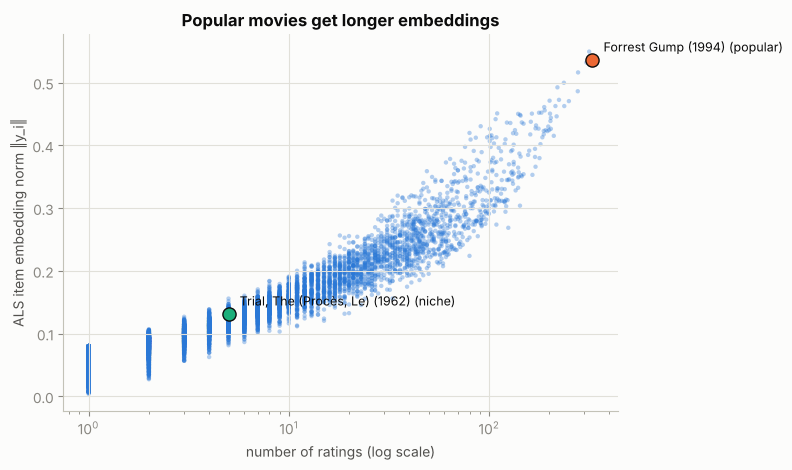

In [38]:
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(pop_col, als_norm, s=10, color=BLUE, alpha=0.35, edgecolor="none", label="each movie")
for mid, label, color in [(POPULAR, "popular", ORANGE), (NICHE, "niche", AQUA)]:
    c = col_of_movie[mid]
    ax.scatter(pop_col[c], als_norm[c], s=90, color=color, edgecolor=INK, linewidth=1, zorder=3)
    ax.annotate(f"{title_of[mid]} ({label})", (pop_col[c], als_norm[c]), xytext=(8, 6), textcoords="offset points",
                color=INK, fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("number of ratings (log scale)")
ax.set_ylabel("ALS item embedding norm ‖y_i‖")
ax.set_title("Popular movies get longer embeddings")
plt.tight_layout(); plt.show()

In [39]:
# What it does to the recommendations of ALL users: dot product vs. cosine scoring
top1pct = set(np.argsort(-pop_col)[: int(0.01 * len(pop_col))])         # the 1% most-rated movies (97 titles)

def topk_from_scores(S, liked, K=10):
    S = S.copy(); S[liked.nonzero()] = -np.inf
    return np.argpartition(-S, K, axis=1)[:, :K]

def concentration(rec_cols, name):
    flat = rec_cols.ravel()
    return {"model / scoring": name,
            "share of rec slots from top-1% popular": np.mean([c in top1pct for c in flat]),
            "distinct movies recommended": len(np.unique(flat)),
            "catalogue coverage": len(np.unique(flat)) / len(pop_col),
            "median # ratings of recs": np.median(pop_col[flat])}

U_als, V_als = als.user_factors, als.item_factors
V_unit = V_als / np.linalg.norm(V_als, axis=1, keepdims=True)
bias_rows = [
    concentration(topk_from_scores(U_als @ V_als.T, C_full), "ALS · dot product"),
    concentration(topk_from_scores(U_als @ V_unit.T, C_full), "ALS · cosine (item norm removed)"),
    concentration(topk_from_scores(bpr.user_factors @ bpr.item_factors.T, B_full), "BPR · dot product + bias"),
]
popularity_bias_table = pd.DataFrame(bias_rows).set_index("model / scoring")
display(popularity_bias_table.round(3))

# Does removing the norm cost accuracy? Same held-out split and α=1 model as Phase 6.3
m1 = als_split[1]
norms1 = np.linalg.norm(m1.item_factors, axis=1, keepdims=True)
V1_unit = m1.item_factors / np.where(norms1 > 0, norms1, 1.0)   # movies with no training interactions have a zero vector
acc_dot = evaluate_topk(m1.user_factors @ m1.item_factors.T, R_tr, R_te)["precision@10"]
acc_cos = evaluate_topk(m1.user_factors @ V1_unit.T, R_tr, R_te)["precision@10"]
print(f"held-out precision@10 - dot product: {acc_dot:.3f} | cosine: {acc_cos:.3f}")

,share of rec slots from top-1% popular,distinct movies recommended,catalogue coverage,median # ratings of recs
model / scoring,,,,
ALS · dot product,0.588,754,0.078,133.0
ALS · cosine (item norm removed),0.233,1762,0.181,57.0
BPR · dot product + bias,0.229,1342,0.138,64.0


held-out precision@10 - dot product: 0.275 | cosine: 0.170


**What the demo shows:**
* **Norm tracks popularity almost perfectly**: Spearman ≈ 0.94 between a movie's number of ratings and its ALS embedding length, and BPR's embeddings show the same pattern.
* *Forrest Gump* (329 ratings) has one of the longest embeddings of all 9,724 movies. *Le Procès* (5 ratings, average 4.9★) has a short one. ALS scores *Forrest Gump* higher for **~98% of users**, even though everyone who watched the niche film loved it. For almost any user vector, the long vector wins the dot product.
* Across all 610 users, **~59% of the 6,100 ALS recommendation slots go to the 1% most-rated movies**, and only ~8% of the catalogue is ever recommended.
* Dividing out the item norm (**cosine** scoring) cuts that share to ~23% and more than doubles catalogue coverage, but at a real cost: held-out precision@10 drops from 0.275 to 0.170, barely above the popularity baseline (0.157). Popular items *are* more likely to be watched next, so part of the norm is genuine signal, not just bias. Real systems tune a middle ground (e.g. `score / ‖y_i‖^β` with 0 < β < 1) or re-rank for diversity. BPR, which scores with its own learned item bias, is much less concentrated than ALS.

### 8.3 The bridge to Task 14
Matrix factorization's two structural weaknesses come from its form: **one fixed dot product between two free embedding tables**.
1. **Side features have nowhere to go.** A new movie's genre, year or cast cannot produce an embedding, so items and users with no history stay cold.
2. **The similarity function is fixed.** The dot product hard-wires the popularity bias seen above, because magnitude and taste are entangled in one number.

**Deep neural recommenders** (Task 14) replace "look up a free vector" with "compute a vector from features". User and item towers take IDs **plus** side features (genres, year, demographics, history), so a brand-new item still gets a meaningful embedding from its metadata. The final score can be a **learned function** (an MLP over both embeddings) or a normalised similarity, instead of a raw dot product. The ideas from this task carry straight over: embeddings learned from interactions, sampled negatives, and pairwise/softmax ranking losses.

---
# Exercises (Must Do)

## Exercise 1 — User-based CF vs. item-based CF vs. matrix factorization on the same held-out split

**Setup.** One random 80/20 split of the ratings, used by every method. Movies with fewer than 20 ratings are dropped first (1,297 movies remain, ~67% of all ratings). The reason is memory: an item-item matrix over all 9,724 movies needs ~750 MB per float64 copy, and the vectorised similarity code makes several copies, too much for a laptop. Test ratings whose user or movie never appears in training are dropped, since no method can score them.

* **User-based CF**: Pearson over co-rated movies (`pearson_corated`, Phase 2), k = 20, mean-centred prediction
* **Item-based CF**: adjusted cosine (`adjusted_cosine`, Phase 3), k = 20 positive neighbours
* **Matrix factorization**: `surprise.SVD`, d = 20, trained on exactly the same training rows
* **Context baselines**: global mean, user's own mean, and the bias-only model $\mu + b_u + b_i$ (`BaselineOnly`)

In [40]:
MIN_RATINGS_EX1 = 20
keep_movies = n_ratings_of.index[n_ratings_of >= MIN_RATINGS_EX1]
ex = ratings[ratings.movieId.isin(keep_movies)].reset_index(drop=True)
perm = np.random.default_rng(SEED).permutation(len(ex))
n_test = int(0.2 * len(ex))
ex_test, ex_train = ex.iloc[perm[:n_test]], ex.iloc[perm[n_test:]]
before = len(ex_test)
ex_test = ex_test[ex_test.userId.isin(ex_train.userId) & ex_test.movieId.isin(ex_train.movieId)]
print(f"{len(keep_movies)} movies, {len(ex):,} ratings ({len(ex)/len(ratings):.0%} of all) | "
      f"train {len(ex_train):,} | test {len(ex_test):,} (dropped {before - len(ex_test)} unscorable)")

R_ex = ex_train.pivot(index="userId", columns="movieId", values="rating")
R_ex_arr = R_ex.values
u_pos = R_ex.index.get_indexer(ex_test.userId)
i_pos = R_ex.columns.get_indexer(ex_test.movieId)
y_true = ex_test.rating.values
user_means_ex = np.nanmean(R_ex_arr, axis=1)

def scores(pred):
    return {"RMSE": np.sqrt(np.mean((pred - y_true) ** 2)), "MAE": np.mean(np.abs(pred - y_true))}

ex1 = {}
ex1["global mean"] = {**scores(np.full(len(y_true), np.nanmean(R_ex_arr))), "coverage": 1.0}
ex1["user's mean"] = {**scores(user_means_ex[u_pos]), "coverage": 1.0}
ex_trainset = Dataset.load_from_df(ex_train[["userId", "movieId", "rating"]], reader).build_full_trainset()
ex_testset = list(zip(ex_test.userId, ex_test.movieId, ex_test.rating))
bl = BaselineOnly(verbose=False); bl.fit(ex_trainset)
ex1["baseline μ + b_u + b_i"] = {**scores(np.array([p.est for p in bl.test(ex_testset)])), "coverage": 1.0}

t0 = time.perf_counter(); sim_u = pearson_corated(R_ex_arr); t_fit = time.perf_counter() - t0
t0 = time.perf_counter()
out = [predict_user_based(R_ex_arr, sim_u, u_, i_, user_means=user_means_ex) for u_, i_ in zip(u_pos, i_pos)]
t_pred = time.perf_counter() - t0
pred = np.array([p for p, _ in out])
ex1["user-based CF"] = {**scores(pred), "coverage": np.mean([n > 0 for _, n in out]),
                        "fit / similarity time (s)": t_fit, "predict time (s)": t_pred}

t0 = time.perf_counter(); sim_i = adjusted_cosine(R_ex_arr); t_fit = time.perf_counter() - t0
t0 = time.perf_counter()
out = [predict_item_based(R_ex_arr, sim_i, u_, i_) for u_, i_ in zip(u_pos, i_pos)]
t_pred = time.perf_counter() - t0
pred = np.array([p for p, _ in out])
ex1["item-based CF"] = {**scores(pred), "coverage": np.mean([n > 0 for _, n in out]),
                        "fit / similarity time (s)": t_fit, "predict time (s)": t_pred}

t0 = time.perf_counter(); mf = SVD(n_factors=20, random_state=SEED); mf.fit(ex_trainset); t_fit = time.perf_counter() - t0
t0 = time.perf_counter(); mf_pred = np.array([p.est for p in mf.test(ex_testset)]); t_pred = time.perf_counter() - t0
ex1["matrix factorization (SVD, d=20)"] = {**scores(mf_pred), "coverage": 1.0,
                                           "fit / similarity time (s)": t_fit, "predict time (s)": t_pred}

ex1_table = pd.DataFrame(ex1).T
print(f"user-user matrix {sim_u.shape} | item-item matrix {sim_i.shape} | coverage = share of test ratings with ≥1 neighbour")
display(ex1_table.round(4))

1297 movies, 67,898 ratings (67% of all) | train 54,319 | test 13,579 (dropped 0 unscorable)


user-user matrix (610, 610) | item-item matrix (1297, 1297) | coverage = share of test ratings with ≥1 neighbour


,RMSE,MAE,coverage,fit / similarity time (s),predict time (s)
global mean,1.0015,0.8026,1.0000,NaN,NaN
user's mean,0.9125,0.7066,1.0000,NaN,NaN
baseline μ + b_u + b_i,0.8415,0.6475,1.0000,NaN,NaN
user-based CF,0.8381,0.6368,0.9948,0.1581,0.7490
item-based CF,0.8515,0.6453,0.9845,0.2263,0.7368
"matrix factorization (SVD, d=20)",0.8358,0.6414,1.0000,0.5001,0.0550


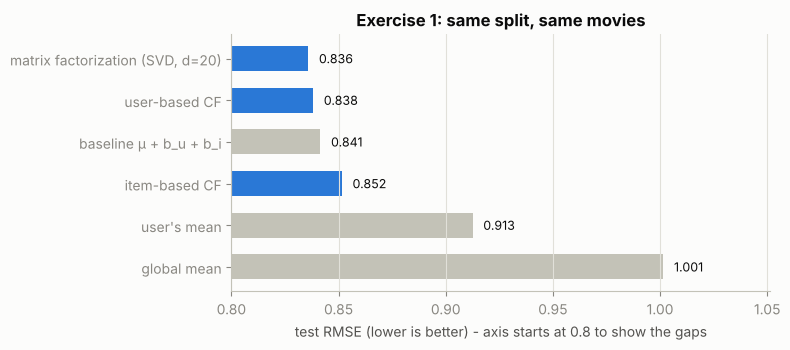

In [41]:
order = ex1_table.sort_values("RMSE", ascending=False)
fig, ax = plt.subplots(figsize=(8, 3.6))
colors = [BLUE if ("CF" in n or "matrix" in n) else AXIS for n in order.index]   # grey = baselines
bars = ax.barh(order.index, order.RMSE, color=colors, height=0.6)
for b_, v_ in zip(bars, order.RMSE):
    ax.text(v_ + 0.005, b_.get_y() + b_.get_height() / 2, f"{v_:.3f}", va="center", color=INK, fontsize=9)
ax.set_xlim(0.8, order.RMSE.max() + 0.05)
ax.set_xlabel("test RMSE (lower is better) - axis starts at 0.8 to show the gaps")
ax.set_title("Exercise 1: same split, same movies")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Findings:**
* **All three collaborative methods beat the global-mean and user-mean baselines by a wide margin** (RMSE ≈ 0.84–0.85 vs. 0.91–1.00), so other users' behaviour clearly helps.
* **The bias-only baseline ($\mu + b_u + b_i$, RMSE 0.842) is the real bar**, and it is a high one. Matrix factorization (0.836) and user-based CF (0.838) clear it only slightly. **Item-based CF (0.852) does not clear it.**
* **Matrix factorization has the lowest error, but only just.** It is 0.002 ahead of user-based CF, which is too small to matter. Its real advantages are practical: it scores **every** test pair (no "no neighbours" fallback), keeps no similarity matrix, and predicts about 10× faster (one dot product per rating instead of a neighbour search).
* **User-based beats item-based here**, and item-based has slightly lower coverage, because the user must have rated a positively-similar movie. That fits this dataset's shape: only 610 users, each with many ratings, so user neighbourhoods are rich, while many movies have only 20–50 raters, so item-item similarities are noisy. Item-based CF's production advantage is **stability and precomputation** (Phase 3.4), not raw accuracy on a static split.

## Exercise 2 — RMSE vs. embedding dimension `d`
Same split as Phase 5 (80/20 of all ratings). Training RMSE is shown next to test RMSE, so the overfitting gap is visible.

,train RMSE,test RMSE,fit time (s),gap (test − train)
d,,,,
5,0.8129,0.8770,0.6518,0.0640
20,0.7766,0.8780,0.7435,0.1014
50,0.7151,0.8775,0.9897,0.1624
100,0.6354,0.8807,1.3579,0.2453


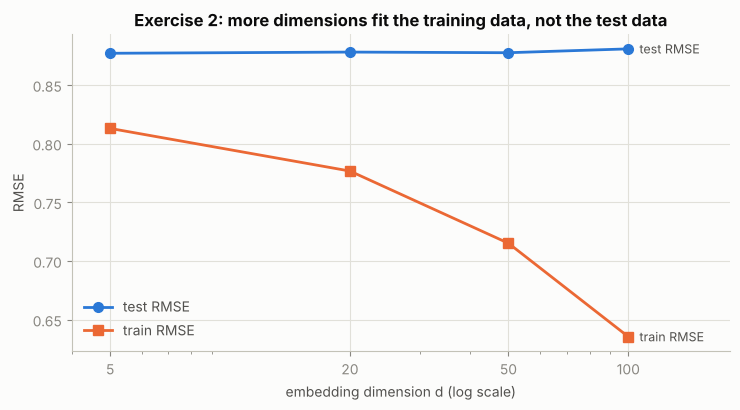

In [42]:
d_rows = []
for d_ in [5, 20, 50, 100]:
    t0 = time.perf_counter()
    m_ = SVD(n_factors=d_, random_state=SEED); m_.fit(trainset)
    fit_s = time.perf_counter() - t0
    d_rows.append({"d": d_, "train RMSE": accuracy.rmse(m_.test(trainset.build_testset()), verbose=False),
                   "test RMSE": accuracy.rmse(m_.test(testset), verbose=False), "fit time (s)": fit_s})
d_table = pd.DataFrame(d_rows).set_index("d")
d_table["gap (test − train)"] = d_table["test RMSE"] - d_table["train RMSE"]
display(d_table.round(4))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(d_table.index, d_table["test RMSE"], color=BLUE, marker="o", label="test RMSE")
ax.plot(d_table.index, d_table["train RMSE"], color=ORANGE, marker="s", label="train RMSE")
for col, color in [("test RMSE", BLUE), ("train RMSE", ORANGE)]:
    ax.annotate(col, (d_table.index[-1], d_table[col].iloc[-1]), xytext=(8, 0), textcoords="offset points",
                color=INK2, va="center", fontsize=9)
ax.set_xscale("log"); ax.set_xticks(d_table.index); ax.set_xticklabels(d_table.index)
ax.set_xlim(4, 180)
ax.set_xlabel("embedding dimension d (log scale)"); ax.set_ylabel("RMSE")
ax.set_title("Exercise 2: more dimensions fit the training data, not the test data")
ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

**Findings:** training RMSE falls steadily as `d` grows, because more parameters memorise the training ratings. **Test RMSE stays flat** (within ~0.005) and is slightly worse at d = 100. The train-test gap widens with `d`, which is classic overfitting. surprise's built-in L2 regularization keeps it from blowing up. On ~80k ratings, most of the predictable signal sits in the **biases** ($\mu + b_u + b_i$) and the first few latent dimensions, so extra dimensions add cost without adding accuracy. Small `d` (5–20) is the right call for a dataset this size.

## Exercise 3 — Cold start: a brand-new user with 2 ratings
Two new users, two ratings each, added **without retraining**:
* **New user K** rated *Toy Story* 5★ and *Finding Nemo* 5★
* **New user H** rated *The Shining* 5★ and *The Exorcist* 5★

**(a) surprise SVD (trained in Phase 5).** The model has no embedding $p_u$ for an unknown user. surprise does not raise an error: for an unknown user it falls back to $\hat r = \mu + b_i$ and ignores the user part entirely.

In [43]:
NEW_USERS = {"new user K": [1, 6377], "new user H": [1258, 1997]}
all_iids = [trainset.to_raw_iid(i_) for i_ in trainset.all_items()]
est = {name: np.array([algo.predict(f"__{name}__", iid).est for iid in all_iids]) for name in NEW_USERS}

print("Identical score for every movie for both new users:", np.array_equal(est["new user K"], est["new user H"]))
print("Score = clip(μ + b_i):", np.allclose(est["new user K"], np.clip(trainset.global_mean + algo.bi, 0.5, 5.0)))
top = np.argsort(-est["new user K"])[:5]
print("Top-5 for BOTH new users (seeds ignored, the same for any newcomer):")
for i_ in top:
    print(f"   {est['new user K'][i_]:.2f}  {title_of[all_iids[i_]]}")

Identical score for every movie for both new users: True
Score = clip(μ + b_i): True
Top-5 for BOTH new users (seeds ignored, the same for any newcomer):
   4.41  Lawrence of Arabia (1962)
   4.38  Shawshank Redemption, The (1994)
   4.38  Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb (1964)
   4.37  Rear Window (1954)
   4.34  Cinema Paradiso (Nuovo cinema Paradiso) (1989)


**(b) Implicit ALS: fold-in without retraining.** With item embeddings $Y$ fixed, the best user vector is exactly **one WALS user step** from Phase 5.3, in closed form:
$$x_u = \big(Y^\top Y + Y^\top (C_u - I) Y + \lambda I\big)^{-1} Y^\top C_u\, p_u$$
`implicit` exposes this as `recommend(..., recalculate_user=True)`. Below we also solve the equation by hand and compare.

In [44]:
def new_user_row(movie_ids, stars=5.0):
    cols = col_of_movie[movie_ids].values
    return csr_matrix((np.full(len(cols), 1 + ALPHA * stars, dtype=np.float32), (np.zeros(len(cols), dtype=int), cols)),
                      shape=(1, len(movie_of_col)))

Y, lam = als.item_factors, als.regularization
fold_in = {}
for name, seeds in NEW_USERS.items():
    row = new_user_row(seeds)
    ids, sc = als.recommend(0, row, N=10, filter_already_liked_items=True, recalculate_user=True)  # userid ignored here
    fold_in[name] = movie_of_col[ids]
    # manual closed-form solve (p_u = 1 on the two seeds, c_u = 1 + α·5 there)
    cols, c = row.indices, row.data
    A_ = Y.T @ Y + lam * np.eye(Y.shape[1]) + (Y[cols].T * (c - 1)) @ Y[cols]
    b_ = (Y[cols].T * c).sum(axis=1)
    x_manual = np.linalg.solve(A_, b_)
    x_lib = np.asarray(als.recalculate_user(0, row)).ravel()
    cos = x_manual @ x_lib / (np.linalg.norm(x_manual) * np.linalg.norm(x_lib))
    S_ = Y @ x_manual; S_[cols] = -np.inf
    overlap = len(set(np.argsort(-S_)[:10]) & set(ids))
    print(f"{name} (seeds: {', '.join(titles(seeds))})")
    print(f"   manual solve vs implicit's recalculate_user: cosine {cos:.4f}, top-10 overlap {overlap}/10")
    for m in fold_in[name]:
        print(f"   - {title_of[m]}   [{'|'.join(genres_of[m])}]")
print("Lists differ between the two new users:", set(fold_in["new user K"]) != set(fold_in["new user H"]))

new user K (seeds: Toy Story (1995), Finding Nemo (2003))
   manual solve vs implicit's recalculate_user: cosine 1.0000, top-10 overlap 10/10
   - Shawshank Redemption, The (1994)   [Crime|Drama]
   - Forrest Gump (1994)   [Comedy|Drama|Romance|War]
   - Silence of the Lambs, The (1991)   [Crime|Horror|Thriller]
   - Matrix, The (1999)   [Action|Sci-Fi|Thriller]
   - Star Wars: Episode IV - A New Hope (1977)   [Action|Adventure|Sci-Fi]
   - Pulp Fiction (1994)   [Comedy|Crime|Drama|Thriller]
   - Schindler's List (1993)   [Drama|War]
   - Lord of the Rings: The Fellowship of the Ring, The (2001)   [Adventure|Fantasy]
   - Lord of the Rings: The Return of the King, The (2003)   [Action|Adventure|Drama|Fantasy]
   - Lord of the Rings: The Two Towers, The (2002)   [Adventure|Fantasy]
new user H (seeds: Shining, The (1980), Exorcist, The (1973))
   manual solve vs implicit's recalculate_user: cosine 1.0000, top-10 overlap 10/10
   - Rosemary's Baby (1968)   [Drama|Horror|Thriller]
   - Psy

**(c) BPR** has no closed-form user step (it is trained by SGD on sampled triples), so `implicit` refuses to fold in a new user:

In [45]:
try:
    bpr.recommend(0, to_binary(new_user_row(NEW_USERS["new user K"])), N=10, recalculate_user=True)
except NotImplementedError as e:
    print("BPR:", type(e).__name__, "-", e)

never_rated = movies[~movies.movieId.isin(ratings.movieId)]
print(f"\nItem cold start: {len(never_rated)} movies in movies.csv have no ratings, so no column and no embedding.")
print("No MF model here can ever recommend them, e.g.:", "; ".join(never_rated.title.head(4)))

BPR: NotImplementedError - recalculate_user is not supported with this model

Item cold start: 18 movies in movies.csv have no ratings, so no column and no embedding.
No MF model here can ever recommend them, e.g.: Innocents, The (1961); Niagara (1953); For All Mankind (1989); Color of Paradise, The (Rang-e khoda) (1999)


**Answer to "can the trained MF model recommend for the new user without retraining?"**
* **surprise SVD: no, not personally.** It returns $\mu + b_i$, the same "generally well-rated movies" list for every newcomer. The 2 ratings are ignored until the model is retrained.
* **ALS: yes, partly.** One closed-form user solve (the WALS step) builds an embedding from 2 interactions in milliseconds, and our hand-solved vector matches the library's fold-in. How useful the result is depends on how informative the 2 interactions are:
  * **New user H** (*The Shining*, *The Exorcist*) gets a clearly horror-flavoured list (*Rosemary's Baby*, *Psycho*, *Poltergeist*, *The Thing*, *Misery*…).
  * **New user K** (*Toy Story*, *Finding Nemo*) gets mostly the **generic popular list** (*Shawshank*, *Forrest Gump*, *The Matrix*, *Lord of the Rings*). Both seeds are themselves mainstream hits, and Phase 6.6 showed that *Toy Story*'s embedding mostly encodes "popular 90s movie". Two popular seeds cannot tell "likes animation" apart from "likes what everyone likes".
* **BPR: no.** It needs retraining or a custom SGD fold-in.
* **New items** with zero interactions cannot be helped by any pure MF model. This is the weakness that feature-based models (Task 14) fix.

## Exercise 4 — ALS vs. BPR top-5 for 3 users
Users: **A** (children's fan) and **B** (horror fan) from Phase 6, plus Phase 2's target user. Agreement categories: **strong** = ≥ 3 of 5 shared, **partial** = 1–2, **none** = 0.

In [46]:
def agreement(n):
    return "strong (≥3/5)" if n >= 3 else ("partial (1-2/5)" if n >= 1 else "none (0/5)")

ex4_rows = []
for uid in [USER_A, USER_B, TARGET_USER]:
    row = row_of_user[uid]
    a_ids, _ = als.recommend(row, C_full[row], N=5)
    b_ids, _ = bpr.recommend(row, B_full[row], N=5)
    shared = set(a_ids) & set(b_ids)
    ex4_rows.append({"user": uid, "ALS top-5": "; ".join(titles(movie_of_col[a_ids])),
                     "BPR top-5": "; ".join(titles(movie_of_col[b_ids])),
                     "shared": len(shared), "agreement": agreement(len(shared))})
display(pd.DataFrame(ex4_rows).set_index("user"))

# The same comparison for every user
all_rows = np.arange(len(user_of_row))
a_all, _ = als.recommend(all_rows, C_full, N=5)
b_all, _ = bpr.recommend(all_rows, B_full, N=5)
shared_all = np.array([len(set(a) & set(b)) for a, b in zip(a_all, b_all)])
dist = pd.Series(shared_all).value_counts().sort_index()
dist_table = pd.DataFrame({"users": dist, "share": dist / len(shared_all)})
dist_table.index.name = "# shared titles in top-5"
display(dist_table.round(3))
cat = pd.Series([agreement(n) for n in shared_all]).value_counts(normalize=True)
print("Agreement over all 610 users:", ", ".join(f"{k}: {v:.0%}" for k, v in cat.items()),
      f"| mean shared = {shared_all.mean():.2f} of 5")

,ALS top-5,BPR top-5,shared,agreement
user,,,,
401,Spirited Away (Sen to Chihiro no kamikakushi) (2001); Ha...,Harry Potter and the Prisoner of Azkaban (2004); Harry P...,4,strong (≥3/5)
571,"Exorcist, The (1973); Friday the 13th (1980); Fly, The (...","Fly, The (1986); Sex, Lies, and Videotape (1989); Superm...",2,partial (1-2/5)
63,"Silence of the Lambs, The (1991); Incredibles, The (2004...","Incredibles, The (2004); V for Vendetta (2006); Iron Man...",3,strong (≥3/5)


,users,share
# shared titles in top-5,,
0,151,0.248
1,190,0.311
2,164,0.269
3,75,0.123
4,29,0.048
5,1,0.002


Agreement over all 610 users: partial (1-2/5): 58%, none (0/5): 25%, strong (≥3/5): 17% | mean shared = 1.42 of 5


**Findings:**
* Pointwise ALS and pairwise BPR mostly **disagree on exact titles**. Over all 610 users, the typical top-5 shares only one or two titles, and only a minority of users get "strong" agreement.
* Where they agree, it is on a user's most distinctive cluster. For the children's fan both converge on the *Harry Potter* series.
* Where they diverge, it is because of what each objective rewards. ALS's squared loss over all cells, with its dot-product popularity effect, pulls in widely watched hits. BPR's sampled pairwise comparisons pull in less popular titles and other patterns, such as the horror fan's era rather than genre (Phase 7.6). Different objectives produce different lists from the same data.

## Exercise 5 — Adjusted cosine from scratch on a 5×5 toy matrix
Pure Python loops and `math.sqrt` only, no NumPy in the core calculation. The toy is designed with a **generous rater** (everything 4–5★) and a **harsh rater** (everything 1–2★), the situation adjusted cosine exists for.

In [47]:
NaN = None
toy = {                                    #  M1   M2   M3   M4   M5
    "U1 (generous)": [5,   4,   5,   NaN, 4],
    "U2 (harsh)":    [2,   1,   2,   1,   NaN],
    "U3":            [4,   2,   NaN, 3,   2],
    "U4":            [NaN, 1,   5,   2,   4],
    "U5":            [5,   2,   4,   2,   NaN],
}
items = ["M1", "M2", "M3", "M4", "M5"]
users = list(toy)

# Step 1: each user's mean over the items they rated
user_mean = {}
for u_ in users:
    vals = [r_ for r_ in toy[u_] if r_ is not None]
    user_mean[u_] = sum(vals) / len(vals)

# Step 2: adjusted cosine for every pair, summing over users who rated BOTH items
def adjusted_cosine_scratch(i, j, verbose=False):
    num = den_i = den_j = 0.0
    for u_ in users:
        ri, rj = toy[u_][i], toy[u_][j]
        if ri is None or rj is None:
            continue
        ci, cj = ri - user_mean[u_], rj - user_mean[u_]
        num += ci * cj
        den_i += ci ** 2
        den_j += cj ** 2
        if verbose:
            print(f"   {u_:<14} mean {user_mean[u_]:.2f} | centred {items[i]} {ci:+.2f}, {items[j]} {cj:+.2f} | product {ci*cj:+.3f}")
    if den_i == 0 or den_j == 0:
        return None
    sim = num / (math.sqrt(den_i) * math.sqrt(den_j))
    if verbose:
        print(f"   numerator {num:.4f} / (√{den_i:.4f} · √{den_j:.4f}) = {sim:.4f}")
    return sim

print("Worked pair M1 vs M2:")
adjusted_cosine_scratch(0, 1, verbose=True)

S_scratch = [[adjusted_cosine_scratch(i, j) for j in range(5)] for i in range(5)]
S_scratch = pd.DataFrame([[np.nan if v is None else v for v in r_] for r_ in S_scratch], index=items, columns=items)
print("\nAdjusted cosine (from scratch):")
display(S_scratch.round(3))

Worked pair M1 vs M2:
   U1 (generous)  mean 4.50 | centred M1 +0.50, M2 -0.50 | product -0.250
   U2 (harsh)     mean 1.50 | centred M1 +0.50, M2 -0.50 | product -0.250
   U3             mean 2.75 | centred M1 +1.25, M2 -0.75 | product -0.938
   U5             mean 3.25 | centred M1 +1.75, M2 -1.25 | product -2.188
   numerator -3.6250 / (√5.1250 · √2.6250) = -0.9883

Adjusted cosine (from scratch):


,M1,M2,M3,M4,M5
M1,1.000,-0.988,0.932,-0.703,-0.979
M2,-0.988,1.000,-0.982,0.847,-0.402
M3,0.932,-0.982,1.000,-0.866,0.759
M4,-0.703,0.847,-0.866,1.000,-0.922
M5,-0.979,-0.402,0.759,-0.922,1.000


In [48]:
# Check 1: identical to the vectorised Phase 3 function (min_common=1 so every co-rated pair is kept)
toy_arr = np.array([[np.nan if v is None else v for v in toy[u_]] for u_ in users], dtype=float)
S_vec = adjusted_cosine(toy_arr, min_common=1)
print("matches Phase 3's adjusted_cosine():", np.allclose(S_scratch.values, S_vec, equal_nan=True))

# Check 2: why "adjusted" matters - plain cosine on raw ratings over the same co-rated users
def plain_cosine(i, j):
    pairs = [(toy[u_][i], toy[u_][j]) for u_ in users if toy[u_][i] is not None and toy[u_][j] is not None]
    num = sum(a * b for a, b in pairs)
    return num / (math.sqrt(sum(a * a for a, _ in pairs)) * math.sqrt(sum(b * b for _, b in pairs)))

compare = pd.DataFrame([{"pair": f"{items[i]}-{items[j]}", "plain cosine": plain_cosine(i, j),
                         "adjusted cosine": S_scratch.iloc[i, j]} for i in range(5) for j in range(i + 1, 5)]).set_index("pair")
display(compare.round(3))

matches Phase 3's adjusted_cosine(): True


,plain cosine,adjusted cosine
pair,,
M1-M2,0.956,-0.988
M1-M3,0.994,0.932
M1-M4,0.956,-0.703
M1-M5,0.978,-0.979
M2-M3,0.892,-0.982
M2-M4,0.969,0.847
M2-M5,0.873,-0.402
M3-M4,0.994,-0.866
M3-M5,1.000,0.759


**Findings:**
* The loop version matches the vectorised Phase 3 function exactly, which confirms that `adjusted_cosine()` implements the formula.
* **Plain cosine on raw ratings is high for every pair** (all ratings are positive, so all vectors point roughly the same way), and it barely separates movies. **Adjusted cosine spreads the pairs from clearly negative to clearly positive.** For example, M1 vs M2 come out *negative*: users who rate M1 above their own average rate M2 below it. Plain cosine calls the same pair very similar, because the generous user's 5 and 4 and the harsh user's 2 and 1 all look like "agreement" in raw numbers.

---
# Deliverables Checklist

- [x] **Phase 1:** written 1-D → 2-D embedding walkthrough, hand-made embedding tables and plot, "learned automatically" statement (1.3–1.6)
- [x] **Phase 2:** user-user Pearson matrix on a 150 × 300 core (verified against pandas and by hand), hand-worked prediction for a held-out rating (2.5–2.6)
- [x] **Phase 3:** item-item adjusted-cosine matrix, hand-worked prediction for the same held-out rating, user- vs. item-based comparison (3.2–3.4)
- [x] **Phase 4:** SVD of a dense toy matrix with reconstruction, and the failure of zero/mean-filled SVD once cells are hidden (4.3–4.5)
- [x] **Phase 5:** WMF objective, SGD and WALS implemented from scratch and compared, w0 study, `surprise.SVD` RMSE, SGD-vs-WALS table (5.1–5.7)
- [x] **Phase 6:** implicit confidence matrix (indexing fixed), α tuned on a held-out split, ALS top-10 for 2 users with history sanity check (6.2–6.7)
- [x] **Phase 7:** BPR assumption and loss, trained BPR, side-by-side with ALS, ranking-metric comparison (7.1–7.6)
- [x] **Phase 8:** strengths/weaknesses table, embedding-norm popularity-bias demonstration, bridge to Task 14 (8.1–8.3)
- [x] **Exercises:** all 5 done (E1–E5)
- [x] **Code:** the notebook runs top to bottom without errors (fixed seeds everywhere; BPR single-threaded so it is reproducible)

In [49]:
key_results = pd.DataFrame([
    ["Phase 2", "user-based CF, held-out rating (true 3.5)", f"{pred_user:.2f}"],
    ["Phase 3", "item-based CF, same held-out rating", f"{pred_item:.2f}"],
    ["Phase 5", "surprise SVD (d=20) test RMSE / BaselineOnly / global mean",
     f"{svd_rmse:.4f} / {baseline_rmse:.4f} / {global_mean_rmse:.4f}"],
    ["Phase 6", "ALS (α=1) precision@10 vs popularity", f"{alpha_table.loc['ALS α=1', 'precision@10']:.3f} vs {alpha_table.loc['popularity baseline', 'precision@10']:.3f}"],
    ["Phase 7", "BPR (100 it.) precision@10", f"{bpr_eval['BPR iterations=100']['precision@10']:.3f}"],
    ["Phase 8", "Spearman(#ratings, ALS item norm)", f"{spearmanr(pop_col, als_norm).correlation:.3f}"],
    ["Ex 1", "test RMSE user-CF / item-CF / MF",
     " / ".join(f"{ex1_table.loc[k_, 'RMSE']:.4f}" for k_ in ["user-based CF", "item-based CF", "matrix factorization (SVD, d=20)"])],
    ["Ex 2", "test RMSE at d = 5 / 20 / 50 / 100", " / ".join(f"{v:.4f}" for v in d_table["test RMSE"])],
    ["Ex 4", "mean ALS-BPR shared titles in top-5 (all users)", f"{shared_all.mean():.2f}"],
], columns=["where", "result", "value"]).set_index("where")
display(key_results)

,result,value
where,,
Phase 2,"user-based CF, held-out rating (true 3.5)",3.91
Phase 3,"item-based CF, same held-out rating",3.96
Phase 5,surprise SVD (d=20) test RMSE / BaselineOnly / global mean,0.8780 / 0.8785 / 1.0446
Phase 6,ALS (α=1) precision@10 vs popularity,0.275 vs 0.157
Phase 7,BPR (100 it.) precision@10,0.186
Phase 8,"Spearman(#ratings, ALS item norm)",0.944
Ex 1,test RMSE user-CF / item-CF / MF,0.8381 / 0.8515 / 0.8358
Ex 2,test RMSE at d = 5 / 20 / 50 / 100,0.8770 / 0.8780 / 0.8775 / 0.8807
Ex 4,mean ALS-BPR shared titles in top-5 (all users),1.42
